In [ ]:
def get_tone(container):
    """Определяет тональность по классу request1/2/3."""
    request_div = container.find(
        "div",
        class_=re.compile(r"^request[123]$")
    )

    if not request_div:
        return "unknown"

    classes = request_div.get("class", [])

    if "request1" in classes:
        return "positive"
    if "request2" in classes:
        return "negative"
    if "request3" in classes:
        return "neutral"

    return "unknown"

In [ ]:
import csv
import requests
from bs4 import BeautifulSoup
import re

universities = []

url = "https://tabiturient.ru/map/"

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"
}

try:
    response = requests.get(url, headers=headers)
    response.raise_for_status()
    response.encoding = 'utf-8'
    soup = BeautifulSoup(response.text, 'html.parser')
    li_elements = soup.select('span.font2 li')
    for li in li_elements:
        link = li.find('a')
        if link:
            href = link.get('href')
            if 'proxodnoi' not in href and 'about' not in href and 'dod' not in href and 'obsh' not in href and 'vuzu' in href and 'ачгаа' not in href and 'билгу' not in href and 'дрти' not in href:
                universities.append(href)

except requests.exceptions.RequestException as e:
    print(f"Ошибка при загрузке страницы: {e}")

universities


['https://tabiturient.ru/vuzu/agatu',
 'https://tabiturient.ru/vuzu/bigpibiysk',
 'https://tabiturient.ru/vuzu/altgaki',
 'https://tabiturient.ru/vuzu/asmu',
 'https://tabiturient.ru/vuzu/agpu',
 'https://tabiturient.ru/vuzu/astu',
 'https://tabiturient.ru/vuzu/agnirt',
 'https://tabiturient.ru/vuzu/adygnet',
 'https://tabiturient.ru/vuzu/asu',
 'https://tabiturient.ru/vuzu/agiki',
 'https://tabiturient.ru/vuzu/alatyrchuvsu',
 'https://tabiturient.ru/vuzu/altspu',
 'https://tabiturient.ru/vuzu/altstu',
 'https://tabiturient.ru/vuzu/altsu',
 'https://tabiturient.ru/vuzu/asau',
 'https://tabiturient.ru/vuzu/alt_ranepa',
 'https://tabiturient.ru/vuzu/fa_barnaul',
 'https://tabiturient.ru/vuzu/spbau',
 'https://tabiturient.ru/vuzu/alfkai',
 'https://tabiturient.ru/vuzu/amursma',
 'https://tabiturient.ru/vuzu/amgpgu',
 'https://tabiturient.ru/vuzu/amursu',
 'https://tabiturient.ru/vuzu/angtu',
 'https://tabiturient.ru/vuzu/mpguanapskiyfilial',
 'https://tabiturient.ru/vuzu/api_nntu',
 'http

In [ ]:
def parse_univ(soup, i):
    words = 0
    symbols = 0

    containers = soup.find_all("div", class_="mobpadd20-2")
    reviews_list = []

    COLOR_MAP = {
        "request1": "positive",
        "request2": "negative",
        "request3": "neutral",
    }

    for container in containers:
        if not container.find("div", class_=re.compile(r"request\d")):
            continue

        tone = get_tone(container)

        text = None
        text_div = container.find(
            "div",
            style=lambda s: s and "text-align:justify" in s,
            class_="font2",
        )
        if text_div:
            text = text_div.get_text(strip=True)

        faculty = None
        b_tag = container.find("b", class_="font11")
        if b_tag:
            faculty = b_tag.get_text(strip=True)
        if faculty == 'Пожалуйста, подождите. Идет загрузка...':
            faculty = 'Факультет не указан'

        person = None
        person_cell = container.find("span", class_="font2")
        if person_cell:
            person = person_cell.get_text(strip=True)

        date = None
        date_icon_cell = container.find("td", class_="dateinrat")

        if date_icon_cell:
            date_text_cell = date_icon_cell.find_next_sibling("td")

            if date_text_cell:
                date_span = date_text_cell.find("span", class_="font2")
                if date_span:
                    date = date_span.get_text(strip=True)
                else:
                    date = date_text_cell.get_text(strip=True)

        views = None
        eye_img = container.find("img", class_="likeimg")
        if eye_img:
            views_icon_cell = eye_img.find_parent("td")
            if views_icon_cell:
                views_text_cell = views_icon_cell.find_next_sibling("td")
                if views_text_cell:
                    views_span = views_text_cell.find("span", class_="font2")
                    if views_span:
                        views = views_span.get_text(strip=True)
                    else:
                        views = views_text_cell.get_text(strip=True)

        useful = None
        useful_cell = container.find("b", id=re.compile(r"^likeval\d+$"))
        if useful_cell:
            useful = useful_cell.get_text(strip=True)

        #if date and ('ноября 2020' in date or 'октября 2020' in date or 'декабря 2020' in date):
        #    print(f"Остановка на дате: {date}")
        #    break

        words += len(text.split())
        symbols += len(text)
        views = views.split()

        reviews_list.append([i.upper(), person[:-1], faculty, text, date, tone, ''.join(views), useful])

    return reviews_list, words, symbols

#parse_hse()

In [ ]:
header = ['University', 'Position', 'Department', 'Feedback', 'Date', 'Tone', 'Views', 'Usefulness']

with open('unis.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow(header)

BASE_URL = "https://tabiturient.ru/ajax/ajsliv.php"

def uni(univer):

    for each in univer:

        headers = {
            "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                        "(KHTML, like Gecko) Chrome/120.0 Safari/537.36",
            "X-Requested-With": "XMLHttpRequest",
            "Referer": each,
            "Accept": "*/*",
        }

        data = {
            "vuzid": re.sub(r".*/vuzu/|/.*", "", each),
            "limit": "1000",
            "sortby": "3",
            "sortby2": "",
        }

        r = requests.post(BASE_URL, headers=headers, data=data, timeout=30)
        print(f"Status: {r.status_code}, size: {len(r.text)} bytes")

        with open(f"{re.sub(r".*/vuzu/|/.*", "", each)}_reviews.html", "w", encoding="utf-8") as f:
            f.write(r.text)

        soup = BeautifulSoup(r.text, "html.parser")

        containers = soup.find_all("div", class_="mobpadd20-2")
        print(f"Найдено контейнеров: {len(containers)}")

        reviews, wordss, symboles = parse_univ(soup, re.sub(r".*/vuzu/|/.*", "", each))
        print(f"Распарсено отзывов: {len(reviews)}")
        print(f'Количество слов {wordss}\nКоличество символов {symboles}')

        with open('unis.csv', 'a', newline='', encoding='utf-8') as f:
            writer = csv.writer(f)
            writer.writerows(reviews)

uni(universities)

Status: 200, size: 46 bytes
Найдено контейнеров: 0
Распарсено отзывов: 0
Количество слов 0
Количество символов 0
Status: 200, size: 46 bytes
Найдено контейнеров: 0
Распарсено отзывов: 0
Количество слов 0
Количество символов 0
Status: 200, size: 7905 bytes
Найдено контейнеров: 1
Распарсено отзывов: 1
Количество слов 534
Количество символов 3532
Status: 200, size: 46 bytes
Найдено контейнеров: 0
Распарсено отзывов: 0
Количество слов 0
Количество символов 0
Status: 200, size: 5557 bytes
Найдено контейнеров: 1
Распарсено отзывов: 1
Количество слов 205
Количество символов 1468
Status: 200, size: 46 bytes
Найдено контейнеров: 0
Распарсено отзывов: 0
Количество слов 0
Количество символов 0
Status: 200, size: 7535 bytes
Найдено контейнеров: 1
Распарсено отзывов: 1
Количество слов 433
Количество символов 3168
Status: 200, size: 6504 bytes
Найдено контейнеров: 1
Распарсено отзывов: 1
Количество слов 299
Количество символов 2047
Status: 200, size: 7364 bytes
Найдено контейнеров: 1
Распарсено отзы

In [ ]:
!pip install pandas numpy scikit-learn scipy

  Using cached pandas-3.0.6-cp314-cp314-win_amd64.whl.metadata (19 kB)
  Using cached numpy-2.5.4-cp314-cp314-win_amd64.whl.metadata (6.6 kB)
   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   ------- -------------------------------- 1.8/9.8 MB 13.8 MB/s eta 0:00:01
   ---------------------------- ----------- 7.1/9.8 MB 21.7 MB/s eta 0:00:01
   ---------------------------------------- 9.8/9.8 MB 21.8 MB/s  0:00:00
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   ----------------- ---------------------- 5.5/12.7 MB 27.4 MB/s eta 0:00:01
   ---------------------------------- ----- 11.0/12.7 MB 27.1 MB/s eta 0:00:01
   ---------------------------------------- 12.7/12.7 MB 24.8 MB/s  0:00:00
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   -------------------------- ------------- 5.5/8.4 MB 27.5 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 22.4 MB/s  0:00:00
   -----------------------------------

In [ ]:
import pandas as pd

with open('unis.csv', 'r', encoding='utf-8') as f:
    f = pd.read_csv('unis.csv')
    df = pd.DataFrame(f)

df.loc[1000:1005]

,University,Position,Department,Feedback,Date,Tone,Views,Usefulness
1000,MGPU,Студент этого вуза,Институт естествознания и спортивных технологий,Поступал в прошлом году на кафедру биологии и ...,10 февраля 2023,negative,150696,56
1001,MGPU,Студент этого вуза,Институт иностранных языков,"МГПУ и кафедра ИИЯ - оплот лицемерия, лакейств...",07 февраля 2023,negative,151472,80
1002,MGPU,Выпускник этого вуза,Институт иностранных языков,О господи. Я училась на факультете востоковеде...,25 декабря 2022,negative,160016,89
1003,MGPU,Студент этого вуза,Институт педагогики и психологии образования,Вообщем. Решила я в этом году поступать в Моск...,01 ноября 2022,negative,167454,98
1004,MGPU,Студент этого вуза,Институт иностранных языков,"Учусь на 3 курсе направления ""педагогическое о...",08 сентября 2022,positive,169220,69
1005,MGPU,Выпускник этого вуза,Институт культуры и искусств,"Дизайн среды. В целом, стоит идти если вам нуж...",09 августа 2022,neutral,175374,37


In [ ]:
import re, unicodedata

df = df.reset_index(drop=True).copy()
df["id"] = df.index

# даты
months = {"января":"01","февраля":"02","марта":"03","апреля":"04","мая":"05","июня":"06",
          "июля":"07","августа":"08","сентября":"09","октября":"10","ноября":"11","декабря":"12"}
def parse_date(s):
    d, m, y = str(s).split()
    return pd.to_datetime(f"{d}.{months[m.lower()]}.{y}", format="%d.%m.%Y", errors="coerce")
df["date"] = df["Date"].map(parse_date)
print("Не распознано дат:", df["date"].isna().sum())
df["year"] = df["date"].dt.year

df = df.rename(columns={"University": "univ", "Position": "author", "Department": "dept",
                        "Feedback": "text_raw", "Tone": "tone",
                        "Views": "views", "Usefulness": "useful"})

df["views"] = pd.to_numeric(df["views"], errors="coerce")
df["useful"] = pd.to_numeric(df["useful"], errors="coerce")

Не распознано дат: 0


In [ ]:
print(df["text_raw"].str.len().describe())
print(df.loc[1000, "text_raw"][:1500])

print(df["univ"].value_counts())
print(df["author"].value_counts())
print(df["tone"].value_counts())

count     3818.000000
mean      3769.937926
std       3206.435234
min        505.000000
25%       1762.000000
50%       2905.000000
75%       4593.250000
max      36541.000000
Name: text_raw, dtype: float64
Поступал в прошлом году на кафедру биологии и физиологии человека. Полученных знаний - 0, вас будут забирать с пар на совершенно ненужные мероприятия, преподаватели совершенно некомпетентны и ленивы, пары очень скучные и совершенно неинформативные. Жаль тех, кто идет сюда учиться за деньги!Расписание надо выбивать в учебном отделе чуть ли не силой, как и остальную информацию. Она постоянно доносится противоречиво, неправильно.Преподаватели будут вам тыкать, звонить, когда пожелают, если с вами поздароваются и НЕ оскорбят вашу личность, то вам крупно повезет.Сто процентная предвзятость, выбор любимчиков-активистов. Если вы идете работать педагогом, но не по профилю обучения, это не будет уважительной причиной и вы получите тонну негатива в свою сторону.Поощряется лишь подхалимство, б

In [ ]:
def clean(t):
    if not isinstance(t, str):
        return ""
    t = re.sub(r"\.{0,3}\s*Показать полностью\s*\.{0,3}", "", t)
    t = unicodedata.normalize("NFKC", t)
    t = re.sub(r"<[^>]+>", " ", t)
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)
    t = re.sub(r"[\u200b-\u200f\ufeff]", "", t)
    t = re.sub(r"Показать полностью\.{0,3}", " ", t)
    t = re.sub(r"(?<=[.!?…»\)\:;])(?=[А-ЯЁA-Z])", "\n", t)
    t = re.sub(r"(?<=[а-яё]{2})(?=[А-ЯЁ][а-яё])", "\n", t)
    t = re.sub(r"(?<!\w)([А-ЯЁA-Z]\.)\n(?=[А-ЯЁA-Z])", r"\1 ", t)
    t = re.sub(r"([!?.])\1{2,}", r"\1\1\1", t)
    t = re.sub(r"(.)\1{4,}", r"\1\1\1", t)
    t = re.sub(r"[ \t]+", " ", t)
    t = re.sub(r"\s*\n\s*", "\n", t).strip()
    return t

df["text_para"] = df["text_raw"].map(clean)
df["text_clean"] = df["text_para"].str.replace("\n", " ", regex=False)
df["n_words"] = df["text_clean"].str.split().str.len()
df["n_par"] = df["text_para"].str.count("\n") + 1

In [ ]:
def norm_key(t):
    return re.sub(r"[^\w]+", " ", t.lower().replace("ё", "е")).strip()

df["key"] = df["text_clean"].map(norm_key)
long_ = df["n_words"] >= 30
dup_mask = long_ & df.duplicated("key", keep=False)
print("Строк в группах точных дублей:", dup_mask.sum())

g = df[dup_mask].groupby("key").agg(n=("id", "size"),
                                    n_univ=("univ", "nunique"),
                                    n_dept=("dept", "nunique"),
                                    first=("date", "min"))
print(g.sort_values("n", ascending=False).head(20))
print((g["n_univ"] > 1).sum(), "групп, где один текст встречается в разных вузах")

Строк в группах точных дублей: 12
                                                    n  n_univ  n_dept  \
key                                                                     
доброго времени суток всем посетителям данного ...  2       1       1   
поступил на юрфак вгу в позапрошлом году сейчас...  2       1       1   
психология вечернее отделение всем добрый день ...  2       1       1   
ребята хочу вам рассказать почему я бросила фж ...  2       1       1   
туалеты хуже чем в некоторых сельских школах об...  2       1       1   
учусь на техносферной безопасности выбирала инс...  2       1       1   

                                                        first  
key                                                            
доброго времени суток всем посетителям данного ... 2023-03-13  
поступил на юрфак вгу в позапрошлом году сейчас... 2016-10-14  
психология вечернее отделение всем добрый день ... 2024-12-05  
ребята хочу вам рассказать почему я бросила фж ... 2022-12-19

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

X = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(df["key"])
S = cosine_similarity(X)
np.fill_diagonal(S, 0)
i, j = np.where(np.triu(S) > 0.80)
near = pd.DataFrame({"a": i, "b": j, "sim": S[i, j]})
near["sim"] = near["sim"].clip(upper=1.0)
near["same_univ"] = df["univ"].values[i] == df["univ"].values[j]
near["n_words_min"] = np.minimum(df["n_words"].values[i], df["n_words"].values[j])
near = near[near["n_words_min"] >= 30].sort_values("sim", ascending=False)

print(near["sim"].describe())
bins = [0.8, 0.85, 0.9, 0.95, 1.0]
print(pd.cut(near["sim"], bins, include_lowest=True).value_counts().sort_index())

count    22.000000
mean      0.973460
std       0.053721
min       0.813206
25%       0.987566
50%       0.996328
75%       0.999965
max       1.000000
Name: sim, dtype: float64
sim
(0.799, 0.85]     2
(0.85, 0.9]       0
(0.9, 0.95]       2
(0.95, 1.0]      18
Name: count, dtype: int64


In [ ]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

TH = 0.85

edges = near.loc[near["sim"] >= TH, ["a", "b"]].values.tolist()

for _, idx in df[dup_mask].groupby("key").groups.items():
    idx = list(idx)
    edges += [[idx[0], k] for k in idx[1:]]

n = len(df)
e = np.array(edges) if edges else np.empty((0, 2), int)
G = coo_matrix((np.ones(len(e)), (e[:, 0], e[:, 1])), shape=(n, n))
_, df["dup_group"] = connected_components(G, directed=False)

keep_ids = (df.sort_values(["dup_group", "n_words", "date"], ascending=[True, False, True])
              .drop_duplicates("dup_group", keep="first")["id"])
removed = df[~df["id"].isin(keep_ids)].copy()
df = df[df["id"].isin(keep_ids)].copy()
print("Удалено дублей:", len(removed), "| осталось:", len(df))

Удалено дублей: 20 | осталось: 3798


In [ ]:
def cyr_share(t):
    letters = re.findall(r"[A-Za-zА-Яа-яЁё]", t)
    return sum(c >= "А" for c in letters) / max(len(letters), 1)

df["cyr"] = df["text_clean"].map(cyr_share)
df["flag_foreign"] = df["cyr"] < 0.5
ads = r"пишите (мне )?в (телеграм|telegram|whatsapp|ватсап)|(диплом\w*|курсов\w*|реферат\w*) на заказ|заказать (диплом|курсов|реферат)"
df["flag_ads"] = df["text_clean"].str.contains(ads, case=False, regex=True)
print(df["flag_ads"].sum())
for t in df.loc[df["flag_ads"], "text_clean"]:
    print("-", t[:300], "\n")

df["include_main"] = (
    df["author"].isin(["Студент этого вуза", "Выпускник этого вуза", "Отчисленный",
                       "Просто человек", "Некто"])
    & ~df["flag_foreign"] & ~df["flag_ads"]
)
print(df["include_main"].sum())

0
3752


C:\Users\qu\AppData\Local\Temp\ipykernel_33656\3728634689.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df["flag_ads"] = df["text_clean"].str.contains(ads, case=False, regex=True)


In [ ]:
log = pd.DataFrame([
    ("исходно", 3818),
    ("после дедупликации", len(df)),
    ("в основном анализе", int(df["include_main"].sum())),
], columns=["шаг", "отзывов"])
print(log)

df.to_pickle("reviews_clean.pkl")
removed.to_pickle("reviews_removed_dups.pkl")

                  шаг  отзывов
0             исходно     3818
1  после дедупликации     3798
2  в основном анализе     3752


In [ ]:
print([c for c in ["include_main", "n_par", "text_para", "univ"] if c not in df.columns])

[]


In [ ]:
main = df[df["include_main"]]

# 1. Вузы: сколько отзывов приходится на вуз
vc = main["univ"].value_counts()
for k in [10, 20, 30, 50]:
    n_univ = (vc >= k).sum()
    n_rev = vc[vc >= k].sum()
    print(f">= {k} отзывов: {n_univ} вузов, {n_rev} отзывов ({n_rev/len(main):.0%})")

# 2. Абзацы: сколько на отзыв
print(main["n_par"].describe())

# 3. Короткие абзацы
paras = (main[["id", "text_para"]]
         .assign(par=main["text_para"].str.split("\n"))
         .explode("par").drop(columns="text_para"))
paras["n_w"] = paras["par"].str.split().str.len()
print("Доля абзацев короче 5 слов:", (paras["n_w"] < 5).mean())
print(paras.loc[paras["n_w"] < 5, "par"].value_counts().head(25))

>= 10 отзывов: 76 вузов, 3339 отзывов (89%)
>= 20 отзывов: 55 вузов, 3049 отзывов (81%)
>= 30 отзывов: 39 вузов, 2661 отзывов (71%)
>= 50 отзывов: 28 вузов, 2218 отзывов (59%)
count    3752.000000
mean        8.771055
std         9.692339
min         1.000000
25%         3.000000
50%         7.000000
75%        11.000000
max       164.000000
Name: n_par, dtype: float64
Доля абзацев короче 5 слов: 0.06341730225774105
par
Всем привет!         18
Плюсы:               12
Итог:                12
Минусы:              11
Здравствуйте!         9
Всем удачи!           8
Добрый день!          8
Вывод:                8
Преподаватели:        8
Обучение.             8
Привет!               8
Преподаватели         7
Подача материала:     7
Поступление.          6
Общежитие.            6
Общежитие             6
Итог                  6
Учеба                 6
Отношение:            6
ИТОГ:                 6
Поступление:          5
Предыстория.          5
Итог.                 5
Общежитие:            5


In [ ]:
main = df[df["include_main"]]
big = main.nlargest(5, "n_par")[["id", "univ", "n_words", "n_par"]]
print(big)
print(main.loc[big.index[0], "text_para"][:800])

        id     univ  n_words  n_par
1801  1801  HSE-SPB     3792    164
2068  2068   RANEPA     1752    140
2903  2903    MUCTR     3330    109
1305  1305     MGUA      967    103
533    533     ISPU     1242     99
Закончил ПМИ 2 курс, поехали. Отзыв конечно положительный, потому что люди и преподы топ/ок, учёба топ, корпус топ, общага ок.
Программа ПАДИ 1 семестр совпадает, МАТАН совпадает, так что тоже читать можно.
У физиков первый курс МАТАН совпадает, ко 2 курсу осталось 9/30, грустно.
САМОЕ ВАЖНОЕНоут - покупал китайский неигровой за 55k в 2023, но если 512 гб брать то где-то к концу 2 семестра пришлось менеджить дико память, так что 1024 лучше.
Что сделать перед обучением - самое главное - это стабильное ментальное состояние. Сделайте то что очень хотели после ЕГЭ.
Потому что если делать хотелки во время учёбы будет допса, перевод в ИТМО/отчисление/призыв/служба по контракту (извините)советую пройти курсы по матану с офиц сайта поступающим на stepic, потому что матан является о

In [ ]:
!pip install razdel
from razdel import sentenize

def build_segments(text_para, min_w=12, max_w=120, tiny=8):
    paras = [p for p in text_para.split("\n") if p.strip()]
    out, buf = [], ""
    for p in paras:
        buf = f"{buf} {p}".strip() if buf else p
        if len(buf.split()) >= min_w:
            out.append(buf); buf = ""
    if buf:
        if out: out[-1] += " " + buf
        else: out.append(buf)

    final = []
    for s in out:
        if len(s.split()) <= max_w:
            final.append(s); continue
        pieces = []
        for sent in (x.text for x in sentenize(s)):
            w = sent.split()
            if len(w) <= max_w:
                pieces.append(sent)
            else:
                pieces += [" ".join(w[k:k+max_w]) for k in range(0, len(w), max_w)]
        chunk = ""
        for sent in pieces:
            if chunk and len((chunk + " " + sent).split()) > max_w:
                final.append(chunk); chunk = sent
            else:
                chunk = f"{chunk} {sent}".strip()
        if chunk: final.append(chunk)


    merged = []
    for s in final:
        if merged and len(s.split()) < tiny:
            merged[-1] += " " + s
        else:
            merged.append(s)
    return merged

main = df[df["include_main"]].copy()
main["segments"] = main["text_para"].map(build_segments)
segs = (main[["id", "univ", "author", "tone", "year", "segments"]]
        .explode("segments").rename(columns={"segments": "segment"}).reset_index(drop=True))
segs["seg_n_words"] = segs["segment"].str.split().str.len()
print(len(segs)); print(segs["seg_n_words"].describe())

df.to_pickle("reviews_clean.pkl"); segs.to_pickle("segments.pkl")

35567
count    35567.000000
mean        59.813451
std         35.268412
min          3.000000
25%         28.000000
50%         52.000000
75%         94.000000
max        127.000000
Name: seg_n_words, dtype: float64


In [ ]:
short = segs.loc[segs["seg_n_words"] < 8, "segment"]
print("< 8 слов:", len(short))
print("> 150 слов:", (segs["seg_n_words"] > 150).sum())
print(short.head(15).tolist())

print(len(segs))
print(segs["seg_n_words"].describe())
segs.to_pickle("segments.pkl")

< 8 слов: 2
> 150 слов: 0
['ну что ж.', 'Я выпускник ФГП МГУ, чувства немного смешанные.']
35567
count    35567.000000
mean        59.813451
std         35.268412
min          3.000000
25%         28.000000
50%         52.000000
75%         94.000000
max        127.000000
Name: seg_n_words, dtype: float64


In [ ]:
df.head(7)

,univ,author,dept,text_raw,Date,tone,views,useful,id,date,...,text_clean,n_words,key,text_para,n_par,dup_group,cyr,flag_foreign,flag_ads,include_main
0,ALTGAKI,Студент этого вуза,Факультет художественного творчества,"Итак, для тех кто необдуманно хочет поступать ...",02 июля 2024,negative,12058,15,0,2024-07-02,...,"Итак, для тех кто необдуманно хочет поступать ...",552,итак для тех кто необдуманно хочет поступать в...,"Итак, для тех кто необдуманно хочет поступать ...",20,0,1.000000,False,False,True
1,AGPU,Выпускник этого вуза,Психолого-педагогический факультет,"Если вы собрались выучиться на психолога, то д...",14 августа 2023,negative,5380,15,1,2023-08-14,...,"Если вы собрались выучиться на психолога, то д...",208,если вы собрались выучиться на психолога то дл...,"Если вы собрались выучиться на психолога, то д...",4,1,1.000000,False,False,True
2,AGNIRT,Студент этого вуза,Факультет экономических и гуманитарных дисциплин,Я поступила в ВШН в 2023 году на 1 курс менедж...,07 марта 2024,positive,22130,39,2,2024-03-07,...,Я поступила в ВШН в 2023 году на 1 курс менедж...,444,я поступила в вшн в 2023 году на 1 курс менедж...,Я поступила в ВШН в 2023 году на 1 курс менедж...,12,2,1.000000,False,False,True
3,ADYGNET,Просто человек,Факультет математики и компьютерных наук,Информации о этом ВУЗе в интернете нет (помимо...,21 августа 2021,neutral,13881,30,3,2021-08-21,...,Информации о этом ВУЗе в интернете нет (помимо...,307,информации о этом вузе в интернете нет помимо ...,Информации о этом ВУЗе в интернете нет (помимо...,9,3,0.991844,False,False,True
4,ASU,Отчисленный,Факультет иностранных языков,"Вышло так, что в 2018 выкатили сложный профиль...",09 января 2021,neutral,15164,35,4,2021-01-09,...,"Вышло так, что в 2018 выкатили сложный профиль...",512,вышло так что в 2018 выкатили сложный профиль ...,"Вышло так, что в 2018 выкатили сложный профиль...",9,4,0.999174,False,False,True
5,ALTSU,Студент этого вуза,Институт истории и международных отношений,"Всем привет. Очень понимаю тех, кто не может о...",21 декабря 2025,negative,74755,23,5,2025-12-21,...,"Всем привет. Очень понимаю тех, кто не может о...",601,всем привет очень понимаю тех кто не может опр...,"Всем привет. Очень понимаю тех, кто не может о...",4,5,0.999026,False,False,True
6,ALTSU,Студент этого вуза,Институт психологии,"АГУ и зря потраченный годНачнем с того, что ты...",30 июня 2024,negative,17099,36,6,2024-06-30,...,"АГУ и зря потраченный год Начнем с того, что т...",292,агу и зря потраченный год начнем с того что ты...,"АГУ и зря потраченный год\nНачнем с того, что ...",11,6,1.000000,False,False,True


In [ ]:
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu128

Looking in indexes: https://download.pytorch.org/whl/cu128
   ---------------------------------------- 0.0/2.8 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.8 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.8 GB 18.8 MB/s eta 0:02:28
   ---------------------------------------- 0.0/2.8 GB 21.5 MB/s eta 0:02:09
   ---------------------------------------- 0.0/2.8 GB 21.7 MB/s eta 0:02:08
   ---------------------------------------- 0.0/2.8 GB 21.4 MB/s eta 0:02:09
   ---------------------------------------- 0.0/2.8 GB 21.9 MB/s eta 0:02:06
   ---------------------------------------- 0.0/2.8 GB 22.6 MB/s eta 0:02:02
   ---------------------------------------- 0.0/2.8 GB 22.8 MB/s eta 0:02:00
    --------------------------------------- 0.0/2.8 GB 23.2 MB/s eta 0:01:59
    --------------------------------------- 0.0/2.8 GB 23.5 MB/s eta 0:01:56
    --------------------------------------- 0.0/2.8 GB 23.8 MB/s eta 0:01:55
    -----------------------------

In [ ]:
import torch
print(torch.__version__, torch.version.cuda)
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0), torch.cuda.get_device_capability(0))   # ждём (12, 0)
x = torch.randn(1000, 1000, device="cuda"); print((x @ x).sum().item())

2.11.0+cu128 12.8
True
NVIDIA GeForce RTX 5060 Ti (12, 0)
45556.51953125


In [ ]:
import numpy as np, torch, time
from sentence_transformers import SentenceTransformer

segs.to_pickle("segments.pkl")

model = SentenceTransformer("intfloat/multilingual-e5-large", device="cuda",
                            model_kwargs={"torch_dtype": torch.float16})
model.max_seq_length = 256

texts = ["passage: " + s for s in segs["segment"]]
t0 = time.time()
emb = model.encode(texts, batch_size=128, show_progress_bar=True, normalize_embeddings=True)
print(f"{time.time()-t0:.0f} с")

assert len(emb) == len(segs)
np.save("emb_e5large.npy", emb)
print(emb.shape, np.isnan(emb).sum())

d:\venv\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1019 11:50:20.856000 33656 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
Batches: 100%|██████████| 278/278 [01:30<00:00,  3.07it/s]


91 с
(35567, 1024) 0


In [ ]:
print(tok(docs[0])[:20])
print(sum(len(tok(d)) > 0 for d in docs[:500]), "из 500 с непустыми токенами")

red = umap_model.fit_transform(emb)
labels = HDBSCAN(min_cluster_size=40, min_samples=10).fit_predict(red)
print("кластеров:", labels.max() + 1, "| доля шума:", (labels == -1).mean())
print(np.bincount(labels[labels >= 0])[:20])

NameError: name 'tok' is not defined

In [ ]:
print(vec.get_params()["min_df"], vec.get_params()["max_df"])

joined = [" ".join(d for d, l in zip(docs, labels) if l == k) for k in range(-1, labels.max() + 1)]
print(len(joined), [len(j) for j in joined[:3]])
X = vec.fit_transform(joined)
print(X.shape)

NameError: name 'vec' is not defined

In [ ]:
import numpy as np, re, pymorphy3
from functools import lru_cache
from umap import UMAP
from sklearn.cluster import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer
from bertopic import BERTopic

emb = np.load("emb_e5large.npy")
assert len(emb) == len(segs)
docs = segs["segment"].tolist()

morph = pymorphy3.MorphAnalyzer()

@lru_cache(maxsize=None)
def lemma(w):
    return morph.parse(w)[0].normal_form

STOP = set("""и в во не что он на я с со как а то все она так его но да ты к у же вы за бы по только ее мне было вот от меня еще нет о из ему теперь когда даже ну вдруг ли если уже или ни быть был него до вас нибудь опять уж вам ведь там потом себя ничего ей может они тут где есть надо ней для мы тебя их чем была сам чтоб без будто чего раз тоже себе под будет ж тогда кто этот того потому этого какой совсем ним здесь этом один почти мой тем чтобы нее сейчас были куда зачем всех никогда можно при наконец два об другой хоть после над больше тот через эти нас про всего них какая много разве три эту моя впрочем хорошо свою этой перед иногда лучше чуть том нельзя такой им более всегда конечно всю между это который очень такой весь свой мочь наш ваш""".split())

def tok(t):
    out = []
    for w in re.findall(r"[а-яё]{3,}", t.lower()):
        l = lemma(w)
        if l not in STOP:
            out.append(l)
    return out

vec = CountVectorizer(tokenizer=tok, lowercase=False, token_pattern=None,
                      ngram_range=(1, 2), min_df=2)

umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0,
                  metric="cosine", random_state=42)
hdb_model = HDBSCAN(min_cluster_size=40, min_samples=10)

topic_model = BERTopic(language="russian", embedding_model=None, umap_model=umap_model,
                       hdbscan_model=hdb_model, vectorizer_model=vec,
                       top_n_words=10, calculate_probabilities=False, verbose=True)
topics, _ = topic_model.fit_transform(docs, embeddings=emb)

segs["topic"] = topics
info = topic_model.get_topic_info()
print("тем:", len(info) - 1, "| доля шума:", (segs["topic"] == -1).mean())
print(info[["Topic", "Count", "Name"]].head(40).to_string())

2026-10-19 11:53:52,906 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-19 11:54:28,778 - BERTopic - Dimensionality - Completed ✓
2026-10-19 11:54:28,780 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-19 11:54:35,461 - BERTopic - Cluster - Completed ✓
2026-10-19 11:54:35,467 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-19 11:54:43,952 - BERTopic - Representation - Completed ✓


тем: 74 | доля шума: 0.4607360755756741
    Topic  Count                                           Name
0      -1  16387              -1_всё_преподаватель_студент_курс
1       0   4954                     0_отзыв_вуз_поступать_сюда
2       1   1104                1_общежитие_комната_общага_жить
3       2   1083             2_язык_английский_немецкий_уровень
4       3    651         3_преподаватель_препод_студент_хороший
5       4    647          4_студенческий_мероприятие_клуб_жизнь
6       5    444                            5_мпг_мгу_мгла_мгпу
7       6    426                  6_пара_расписание_день_неделя
8       7    407           7_программирование_лаба_семестр_курс
9       8    406               8_аудитория_корпус_здание_ремонт
10      9    391                 9_балл_экзамен_автомат_система
11     10    369              10_физр_физкультура_секция_ходить
12     11    311                        11_спбгу_спбгэу_вшм_вуз
13     12    307       12_преподаватель_экзамен_студент_человек


In [ ]:
segs.to_pickle("segments_topics.pkl")
topic_model.save("bertopic_e5large", serialization="pickle")

big = info[info.Topic >= 0].head(25)
for t, name in zip(big.Topic, big.Name):
    print(f"\n=== {name} ({(segs.topic == t).sum()})")
    for s in segs.loc[segs.topic == t, "segment"].sample(3, random_state=1):
        print("-", s[:250].replace("\n", " "))

print("\n=== ШУМ")
for s in segs.loc[segs.topic == -1, "segment"].sample(10, random_state=1):
    print("-", s[:250].replace("\n", " "))

2026-10-19 11:56:26,236 - BERTopic - WARNING: When you use `pickle` to save/load a BERTopic model,please make sure that the environments in which you saveand load the model are **exactly** the same. The version of BERTopic,its dependencies, and python need to remain the same.


AttributeError: 'DataFrame' object has no attribute 'topic'

In [ ]:
JUNK = {5, 6, 24, 7, 14, 17, 25, 30, 33, 37, 10, 23}


stopish = {"отзыв", "спасибо", "надеяться", "поступать", "рассказать", "хотеть", "данный"}
def auto_junk(name):
    words = name.split("_")[1:]
    return any(w in stopish for w in words)

auto = {t for t, n in zip(info.Topic, info.Name) if t >= 0 and auto_junk(n)}
print("автопометка:", sorted(auto - JUNK))

JUNK_ALL = JUNK | auto
segs["is_junk"] = segs.topic.isin(JUNK_ALL)
keep = (~segs.is_junk & (segs.topic >= 0)).values

print("убрано тем:", len(JUNK_ALL), "| сегментов:", segs.is_junk.sum())
print("осталось тематических сегментов:", keep.sum(), "из", len(segs))

автопометка: [0, 28, 62]


AttributeError: 'DataFrame' object has no attribute 'topic'

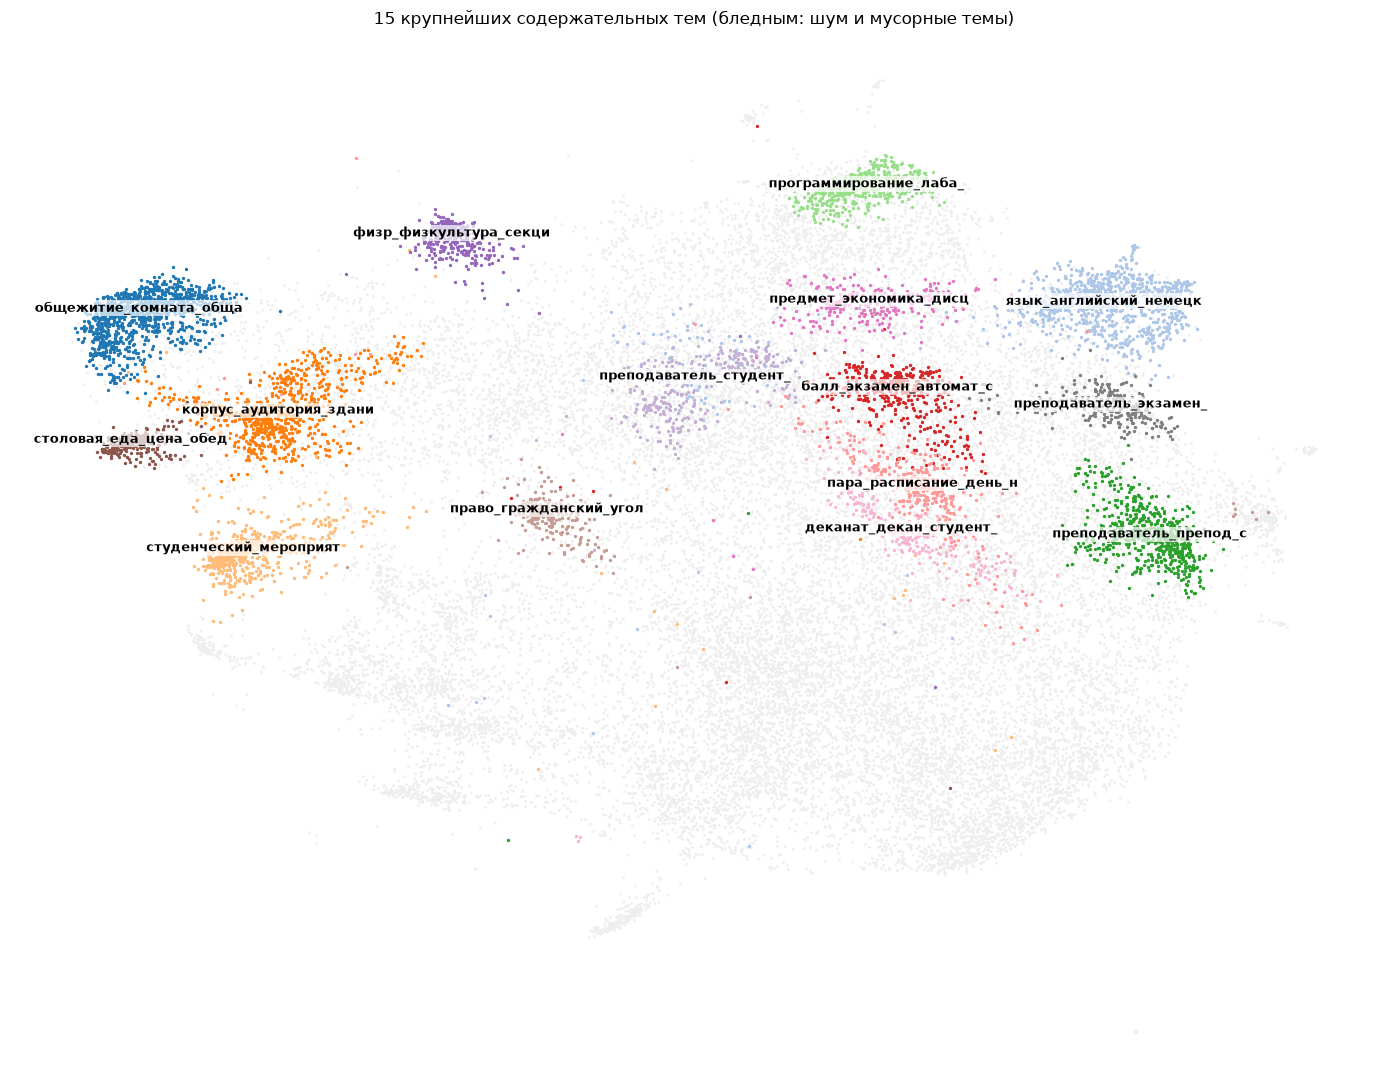

In [ ]:
info_k = info[(info.Topic >= 0) & ~info.Topic.isin(JUNK_ALL)]
top15 = info_k.head(15)

fig, ax = plt.subplots(figsize=(14, 11))
ax.scatter(xy[~keep, 0], xy[~keep, 1], s=1, c="#eeeeee", rasterized=True)
for k, (t, name) in enumerate(zip(top15.Topic, top15.Name)):
    m = (segs.topic == t).values
    ax.scatter(xy[m, 0], xy[m, 1], s=2, color=plt.get_cmap("tab20")(k), rasterized=True)
    cx, cy = np.median(xy[m], axis=0)
    ax.text(cx, cy, name.split("_", 1)[1][:22], fontsize=9, weight="bold",
            ha="center", bbox=dict(fc="white", alpha=0.7, lw=0, pad=1))
ax.set_title("15 крупнейших содержательных тем (бледным: шум и мусорные темы)")
ax.axis("off"); plt.tight_layout(); plt.show()

In [ ]:
import torch, gc
del model
gc.collect(); torch.cuda.empty_cache()

In [ ]:
import json

CODEBOOK = {
    1: "Преподаватели: компетентность и качество преподавания",
    2: "Преподаватели: отношение к студентам (хамство, давление, снобизм)",
    3: "Программа и содержание курсов (устарело, ненужные предметы, дублирование)",
    4: "Экзамены, зачёты, оценивание, баллы, пересдачи",
    5: "Нагрузка",
    6: "Расписание и посещаемость (окна, пары в 8 утра)",
    7: "Деканат, администрация, бюрократия, очереди",
    8: "Коррупция, взятки, покупка оценок и работ",
    9: "Общежитие",
    10: "Здания, аудитории, ремонт, оборудование",
    11: "Столовая и питание",
    12: "Стоимость обучения, платное и бюджет, переводы",
    13: "Стипендия и материальная поддержка",
    14: "Физкультура",
    15: "Иностранные языки",
    16: "Практика и трудоустройство",
    17: "Диплом, научный руководитель, наука",
    18: "Студенческая жизнь и мероприятия",
    19: "Отчисление и угроза отчисления",
    20: "Репутация вуза и ценность диплома",
    21: "Расположение и транспорт",
    22: "Военная кафедра",
    23: "Дистанционное обучение",
    24: "Одногруппники и студенческая среда (отношения, поведение других студентов)",
}
json.dump(CODEBOOK, open("codebook.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)

gold = segs.sample(300, random_state=7)[["segment"]].copy()
gold.insert(0, "seg_idx", gold.index)
gold["polarity"] = ""      # ж = жалоба, н = нейтрально, п = похвала
gold["cats"] = ""
gold.to_csv("gold_to_label.csv", index=False, encoding="utf-8-sig", sep=";")
print(len(gold))

300


In [ ]:
import torch, gc
try: del model
except NameError: pass
gc.collect(); torch.cuda.empty_cache()

In [ ]:
import requests
print(requests.get("http://localhost:11434/api/tags").json()["models"][0]["name"])

qwen2.5:14b


In [ ]:
import json, re, requests, pandas as pd, numpy as np
from sklearn.metrics import classification_report, precision_recall_fscore_support
from sklearn.preprocessing import MultiLabelBinarizer

CODEBOOK = json.load(open("codebook.json", encoding="utf-8"))
CODEBOOK = {int(k): v for k, v in CODEBOOK.items()}

cb_text = "\n".join(f"{k}. {v}" for k, v in CODEBOOK.items())

SYSTEM = f"""Ты размечаешь фрагменты студенческих отзывов о вузах.

Для фрагмента определи:
1) polarity:
 - "ж": в тексте есть ЛЮБАЯ критика, недовольство или упоминание проблемы, даже мягкое, вскользь, внутри описания или рядом с похвалой. Сомневаешься между "ж" и "н" — выбирай "ж".
 - "п": только похвала, никаких претензий.
 - "н": нет ни похвалы, ни критики (факты, вступления, прощания, общий совет без причины).
2) cats: номера категорий, на которые автор ЖАЛУЕТСЯ (только для "ж", иначе []).

Категории:
{cb_text}

Правила для cats:
- Ставь категорию, только если автор жалуется именно на это. Если он пишет, что проблемы нет («взяток нет», «столовая хорошая») или пересказывает слух («говорят, тараканы», «не жил, не знаю») — НЕ ставь её.
- Выбирай 1–3 самые точные категории. Не добавляй соседние «на всякий случай».
- 1: преподаватель плохо учит, некомпетентен, не приходит. 2: хамит, унижает, давит, придирается.
- 3: что и как преподают: бесполезные или устаревшие предметы, нет практики на занятиях, нет нужных курсов.
- 4: экзамены, зачёты, баллы, автоматы, пересдачи, списывание. 5: слишком сложно, перегруз, стресс, нет времени.
- 7: деканат, администрация, очереди за справками, документы, плохая организация. 9: общежитие (места, условия, заселение).
- 10: здания, помещения, туалеты, мебель, оборудование, техника, интернет. 11: ТОЛЬКО еда и столовая.
- 12: цена обучения, платные доп. курсы, переводы, платное и бюджет. 16: практика, стажировки, трудоустройство.
- 20: общее «вуз плохой», «не поступайте», слабый диплом и престиж. 21: расположение вуза, дорога, транспорт, удалённость.
- 6: расписание, окна между парами, ранние пары, вторая смена, обязательная посещаемость.
- 12: ТОЛЬКО деньги за обучение: цена, платные доп. услуги и курсы, переход с платного на бюджет. Дороговизна жизни в городе — не 12.
- 13: стипендия и материальная помощь. Ставь только если стипендия названа прямо.
- 16: практика, стажировки, поиск работы, связи с работодателями.
- 19: ТОЛЬКО факт или угроза отчисления, долги, «выгнать». Ставь только если это сказано прямо.
- 24: другие студенты: одногруппники, их уровень, поведение, атмосфера в группе, «контингент».

Примеры:
"Столовой в корпусе нет, кафе дорогое" -> {{"polarity":"ж","cats":[11]}}
"Лекции интересные, но расписание неудобное, окна по 3 часа" -> {{"polarity":"ж","cats":[6]}}
"Взятки никто не требует. В общежитии, говорят, тараканы, но я не жил." -> {{"polarity":"н","cats":[]}}
"Мне ехать до института два часа" -> {{"polarity":"ж","cats":[21]}}
"Преподаватели профессионалы, всё понятно" -> {{"polarity":"п","cats":[]}}
"Я закончила этот вуз и хочу рассказать о нём" -> {{"polarity":"н","cats":[]}}
"Одногруппники в большинстве ленивые, пришли за корочкой" -> {{"polarity":"ж","cats":[24]}}
"Пары в 8 утра, потом окно три часа" -> {{"polarity":"ж","cats":[6]}}
Отвечай только JSON."""

SCHEMA = {"type": "object",
          "properties": {"polarity": {"type": "string", "enum": ["ж", "н", "п"]},
                         "cats": {"type": "array", "items": {"type": "integer"}}},
          "required": ["polarity", "cats"]}

def label(seg, model="qwen2.5:14b"):
    r = requests.post("http://localhost:11434/api/chat", json={
        "model": model, "stream": False, "format": SCHEMA,
        "options": {"temperature": 0, "num_ctx": 4096},
        "messages": [{"role": "system", "content": SYSTEM},
                     {"role": "user", "content": seg}]}, timeout=120)
    out = json.loads(r.json()["message"]["content"])
    cats = sorted({c for c in out["cats"] if c in CODEBOOK}) if out["polarity"] == "ж" else []
    return out["polarity"], cats

open("D:/venv/system_prompt.txt", "w", encoding="utf-8").write(SYSTEM)

3768

In [ ]:
g = pd.read_csv("gold.csv", sep=";", encoding="utf-8-sig", dtype=str)
g = g[g.polarity.notna()].reset_index(drop=True)
g["cats_t"] = g.cats.fillna("").map(lambda s: sorted(int(x) for x in re.findall(r"\d+", s)))
dev, test = g.iloc[:50].copy(), g.iloc[50:].copy()
print(len(g), len(dev), len(test))

def evaluate(df, model="qwen2.5:14b"):
    pred = [label(s, model) for s in df.segment]
    df = df.assign(p_pol=[p for p, _ in pred], p_cats=[c for _, c in pred])
    print("polarity accuracy:", (df.p_pol == df.polarity).mean())
    print(classification_report(df.polarity, df.p_pol, zero_division=0))
    mlb = MultiLabelBinarizer(classes=list(CODEBOOK))
    y, p = mlb.fit_transform(df.cats_t), mlb.transform(df.p_cats)
    P, R, F, _ = precision_recall_fscore_support(y, p, average="micro", zero_division=0)
    print(f"категории micro: P={P:.2f} R={R:.2f} F1={F:.2f}")
    return df

dev_res = evaluate(dev)

150 50 100
polarity accuracy: 0.88
              precision    recall  f1-score   support

           ж       0.95      0.95      0.95        37
           н       0.64      0.78      0.70         9
           п       1.00      0.50      0.67         4

    accuracy                           0.88        50
   macro avg       0.86      0.74      0.77        50
weighted avg       0.89      0.88      0.88        50

категории micro: P=0.51 R=0.62 F1=0.56


In [ ]:
miss = dev_res[(dev_res.polarity == "ж") & (dev_res.p_pol != "ж")]
print(len(miss), "жалоб пропущено")
for _, r in miss.head(8).iterrows():
    print(f"\n[{r.p_pol}] {r.segment[:350]}\n  разметка: {r.cats_t}")

bad = dev_res[(dev_res.polarity == "ж") & (dev_res.p_pol == "ж") & (dev_res.cats_t.map(tuple) != dev_res.p_cats.map(tuple))]
print("\n=== жалоба найдена, категории не совпали:", len(bad))
for _, r in bad.head(8).iterrows():
    print(f"\n{r.segment[:300]}\n  разметка: {r.cats_t} | модель: {r.p_cats}")

11 жалоб пропущено

[н] Как говориться: Чтобы вылететь из МАИ ,нужны крылья.5) В моем случае расположение института- мне ехать 1.5-2 часа.
  разметка: [21]

[н] Вывод: Вы никогда не угадаете, какой преподаватель вам попадется. Вы никогда не угадаете, что будет у вас в программе, и как вас будут учить, и даже, если вам будут все рассказывать старшекурсники, они не смогут передать всю ту кучу эмоций, которые вы сами получите чуть позже. Если вы достаточно везучий человек, можете проверить свою удачу, но не с
  разметка: [1, 3]

[н] Из группы один человек (!) связал свою профессиональную деятельность с этим языком, посещая занятия в организации, не имеющий к вузу никакого отношения.
  разметка: [16]

[н] По фактам: в МИФИ есть два факультета (институтами их зачем-то называют), которые говорят, что учат проге - ИИКС и ИФТЭБ. НО: на ИФТЭБ нет программирования и любых других курсов по инфотеху. Те курсы, что есть - их ведут преподы с ИИКС.
  разметка: [3]

[п] Материала дается достаточно, ка

In [ ]:
%%time
test_res = evaluate(test)

mlb = MultiLabelBinarizer(classes=list(CODEBOOK))
y, p = mlb.fit_transform(test_res.cats_t), mlb.transform(test_res.p_cats)
P, R, F, S = precision_recall_fscore_support(y, p, zero_division=0)
rep = pd.DataFrame({"cat": list(CODEBOOK), "название": [CODEBOOK[c][:35] for c in CODEBOOK],
                    "P": P.round(2), "R": R.round(2), "F1": F.round(2), "в эталоне": S})
print(rep[rep["в эталоне"] + p.sum(0) > 0].to_string(index=False))

polarity accuracy: 0.87
              precision    recall  f1-score   support

           ж       0.92      0.97      0.94        70
           н       0.68      0.71      0.70        21
           п       1.00      0.44      0.62         9

    accuracy                           0.87       100
   macro avg       0.87      0.71      0.75       100
weighted avg       0.88      0.87      0.86       100

категории micro: P=0.60 R=0.70 F1=0.65
 cat                            название    P    R   F1  в эталоне
   1 Преподаватели: компетентность и кач 0.63 0.60 0.62         20
   2 Преподаватели: отношение к студента 0.42 0.67 0.52         12
   3 Программа и содержание курсов (уста 0.87 1.00 0.93         13
   4 Экзамены, зачёты, оценивание, баллы 0.60 0.82 0.69         11
   5                            Нагрузка 0.44 0.67 0.53          6
   6 Расписание и посещаемость (окна, па 0.67 0.40 0.50          5
   7 Деканат, администрация, бюрократия, 0.91 0.83 0.87         12
   8 Коррупция, взят

In [ ]:
import json, numpy as np, pandas as pd

CB = {int(k): v for k, v in json.load(open("codebook.json", encoding="utf-8")).items()}
CB.update({22: "Военная кафедра", 23: "Дистанционное обучение", 24: "Одногруппники и студенческая среда"})
CATS = sorted(CB)
cols = [f"c{c}" for c in CATS]

segs = pd.read_pickle("segments_topics.pkl")
lab = pd.DataFrame([json.loads(l) for l in open("labels.jsonl", encoding="utf-8")]).set_index("i")
segs = segs.join(lab)
assert segs.pol.notna().all() and (segs.pol != "err").all()

for c in CATS:
    segs[f"c{c}"] = segs.cats.map(lambda l: c in l)

rev = segs.groupby("id")[cols].max()
rev["complaint"] = segs.groupby("id").pol.apply(lambda s: (s == "ж").any())
rev = rev.join(segs.groupby("id")[["univ", "author", "tone", "year"]].first())
print("отзывов:", len(rev), "| с жалобой:", rev.complaint.mean().round(3))

M = rev[cols].to_numpy(dtype=float)
rng = np.random.default_rng(0)
boot = np.array([M[rng.integers(0, len(M), len(M))].mean(0) for _ in range(1000)])
res = pd.DataFrame({"cat": CATS, "название": [CB[c][:45] for c in CATS],
                    "доля отзывов": M.mean(0).round(3),
                    "CI 2.5%": np.percentile(boot, 2.5, 0).round(3),
                    "CI 97.5%": np.percentile(boot, 97.5, 0).round(3),
                    "доля сегментов": segs[cols].mean().round(3).values}
                   ).sort_values("доля отзывов", ascending=False)
print(res.to_string(index=False))

отзывов: 3752 | с жалобой: 0.972
 cat                                      название  доля отзывов  CI 2.5%  CI 97.5%  доля сегментов
   1 Преподаватели: компетентность и качество преп         0.708    0.692     0.723           0.173
   2 Преподаватели: отношение к студентам (хамство         0.678    0.664     0.693           0.176
   3 Программа и содержание курсов (устарело, нену         0.642    0.626     0.657           0.159
  20             Репутация вуза и ценность диплома         0.569    0.554     0.585           0.115
   4 Экзамены, зачёты, оценивание, баллы, пересдач         0.535    0.519     0.550           0.123
   7   Деканат, администрация, бюрократия, очереди         0.524    0.508     0.540           0.116
   5                                      Нагрузка         0.463    0.447     0.480           0.088
  10       Здания, аудитории, ремонт, оборудование         0.384    0.368     0.398           0.063
  12 Стоимость обучения, платное и бюджет, перевод         0.317   

In [ ]:
nseg = segs.groupby("id")[cols].sum()
cmp = pd.DataFrame({
    "cat": CATS, "название": [CB[c][:40] for c in CATS],
    "сегменты": segs[cols].mean().round(3).values,
    "отзывы ≥1": (nseg >= 1).mean().round(3).values,
    "отзывы ≥2": (nseg >= 2).mean().round(3).values,
})
for c in ["сегменты", "отзывы ≥1", "отзывы ≥2"]:
    cmp["ранг " + c.split()[0] + (c.split()[1] if len(c.split()) > 1 else "")] = cmp[c].rank(ascending=False).astype(int)
print(cmp.sort_values("отзывы ≥2", ascending=False).to_string(index=False))

print(segs.groupby("tone").pol.apply(lambda s: (s == "ж").mean()).round(3))

 cat                                 название  сегменты  отзывы ≥1  отзывы ≥2  ранг сегменты  ранг отзывы≥1  ранг отзывы≥2
   1 Преподаватели: компетентность и качество     0.173      0.708      0.409              2              1              1
   2 Преподаватели: отношение к студентам (ха     0.176      0.678      0.404              1              2              2
   3 Программа и содержание курсов (устарело,     0.159      0.642      0.356              3              3              3
  20        Репутация вуза и ценность диплома     0.115      0.569      0.295              6              4              4
   7 Деканат, администрация, бюрократия, очер     0.116      0.524      0.264              5              6              5
   4 Экзамены, зачёты, оценивание, баллы, пер     0.123      0.535      0.261              4              5              6
   5                                 Нагрузка     0.088      0.463      0.194              7              7              7
  10  Здания, ау

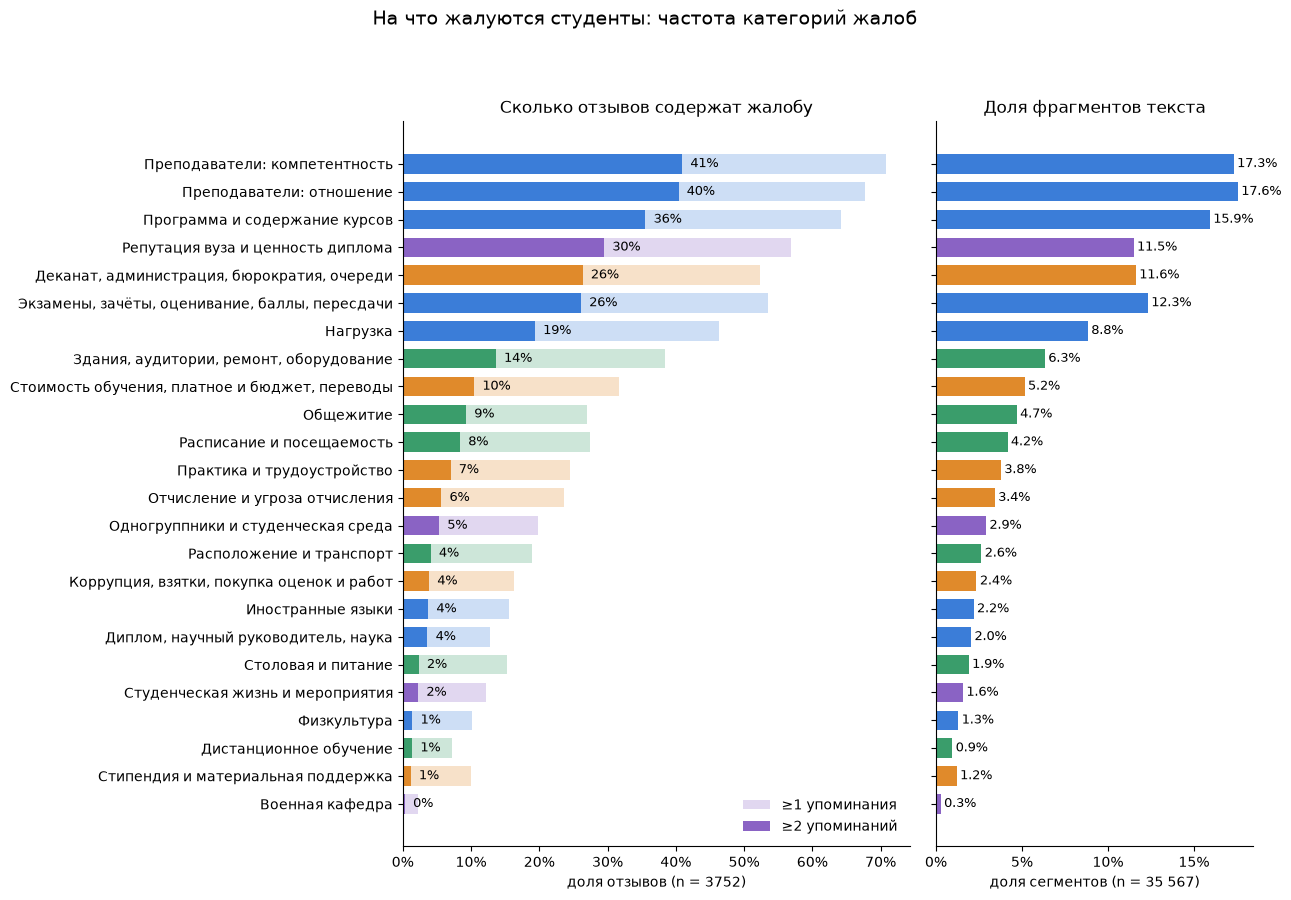

In [ ]:
import matplotlib.pyplot as plt

GROUP = {
    "Преподавание и учёба": [1, 2, 3, 4, 5, 15, 17, 14],
    "Администрация и деньги": [7, 12, 13, 8, 19, 16],
    "Быт и инфраструктура": [9, 10, 11, 21, 6, 23],
    "Репутация и среда": [20, 18, 24, 22],
}
COLOR = {"Преподавание и учёба": "#3b7dd8", "Администрация и деньги": "#e08a2b",
         "Быт и инфраструктура": "#3a9d6b", "Репутация и среда": "#8a63c4"}
grp = {c: g for g, cs in GROUP.items() for c in cs}

M1 = (nseg >= 1).to_numpy(float); M2 = (nseg >= 2).to_numpy(float)
rng = np.random.default_rng(0)
idx = [rng.integers(0, len(M2), len(M2)) for _ in range(1000)]
b2 = np.array([M2[i].mean(0) for i in idx])
lo, hi = np.percentile(b2, 2.5, 0), np.percentile(b2, 97.5, 0)

d = pd.DataFrame({"cat": CATS, "m1": M1.mean(0), "m2": M2.mean(0), "lo": lo, "hi": hi,
                  "seg": segs[cols].mean().values})
d["label"] = [CB[c].split(" (")[0].split(":")[0] if c not in (1, 2) else
              ("Преподаватели: компетентность" if c == 1 else "Преподаватели: отношение")
              for c in d.cat]
d = d.sort_values("m2").reset_index(drop=True)
col = [COLOR[grp[c]] for c in d.cat]
y = np.arange(len(d))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 9), sharey=True,
                               gridspec_kw={"width_ratios": [1.6, 1]})
ax1.barh(y, d.m1, color=col, alpha=0.25, height=0.7, label="≥1 упоминания")
ax1.barh(y, d.m2, color=col, height=0.7, label="≥2 упоминаний")
for yi, v in zip(y, d.m2):
    ax1.text(v + 0.012, yi, f"{v:.0%}", va="center", fontsize=9)
ax1.set_yticks(y); ax1.set_yticklabels(d.label)
ax1.set_xlabel("доля отзывов (n = 3752)"); ax1.set_title("Сколько отзывов содержат жалобу")
ax1.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax1.legend(loc="lower right", frameon=False)

ax2.barh(y, d.seg, color=col, height=0.7)
for yi, v in zip(y, d.seg):
    ax2.text(v + 0.002, yi, f"{v:.1%}", va="center", fontsize=9)
ax2.set_xlabel("доля сегментов (n = 35 567)"); ax2.set_title("Доля фрагментов текста")
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COLOR.values()]
for a in (ax1, ax2):
    a.spines[["top", "right"]].set_visible(False)
fig.suptitle("На что жалуются студенты: частота категорий жалоб", y=0.995, fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("complaints_frequency.png", dpi=150)
plt.show()

In [ ]:
from scipy.stats import fisher_exact

def pairs(M, names, min_n=30):
    M = np.asarray(M, bool); N = len(M); rows = []
    for a in range(M.shape[1]):
        for b in range(a + 1, M.shape[1]):
            n11 = (M[:, a] & M[:, b]).sum(); na, nb = M[:, a].sum(), M[:, b].sum()
            if n11 < min_n: continue
            n10, n01 = na - n11, nb - n11; n00 = N - n11 - n10 - n01
            lift = n11 * N / (na * nb)
            phi = (n11 * n00 - n10 * n01) / np.sqrt(float(na) * nb * (N - na) * (N - nb))
            p = fisher_exact([[n11, n10], [n01, n00]], alternative="greater")[1]
            rows.append((names[a], names[b], n11, round(lift, 2), round(phi, 3), p))
    d = pd.DataFrame(rows, columns=["A", "B", "вместе", "lift", "phi", "p"])
    o = d.p.argsort().to_numpy(); m = len(d)
    adj = np.minimum.accumulate((d.p.to_numpy()[o] * m / np.arange(1, m + 1))[::-1])[::-1]
    d.loc[d.index[o], "p_adj"] = np.minimum(adj, 1)
    return d.sort_values("phi", ascending=False)

short = {c: f"{c}. {CB[c][:22]}" for c in CATS}
names = [short[c] for c in CATS]

seg_pairs = pairs(segs[cols].to_numpy(), names, min_n=30)
print("=== внутри одного сегмента: топ-15 по phi")
print(seg_pairs[seg_pairs.p_adj < 0.05].head(15).to_string(index=False))

rev2 = (nseg >= 2).to_numpy()
rev_pairs = pairs(rev2, names, min_n=30)
print("\n=== внутри одного отзыва (≥2 упоминаний): топ-15 по phi")
print(rev_pairs[rev_pairs.p_adj < 0.05].head(15).to_string(index=False))

=== внутри одного сегмента: топ-15 по phi
                         A                          B  вместе  lift   phi             p         p_adj
 1. Преподаватели: компете  2. Преподаватели: отношен    3648  3.37 0.501  0.000000e+00  0.000000e+00
 4. Экзамены, зачёты, оцен                5. Нагрузка    1227  3.17 0.253  0.000000e+00  0.000000e+00
10. Здания, аудитории, рем     11. Столовая и питание     269  6.27 0.191 4.382322e-144 1.862487e-142
 1. Преподаватели: компете  3. Программа и содержание    1822  1.86 0.171 1.140201e-199 6.461138e-198
              9. Общежитие 21. Расположение и транспо     217  4.93 0.143  1.914058e-89  4.067373e-88
              9. Общежитие 10. Здания, аудитории, рем     359  3.39 0.138  2.296443e-99  5.577076e-98
 3. Программа и содержание                5. Нагрузка     992  1.98 0.133 2.455938e-117 8.350188e-116
 2. Преподаватели: отношен  7. Деканат, администрация    1285  1.77 0.129 9.794433e-115 2.775089e-113
10. Здания, аудитории, рем 21. Расположе

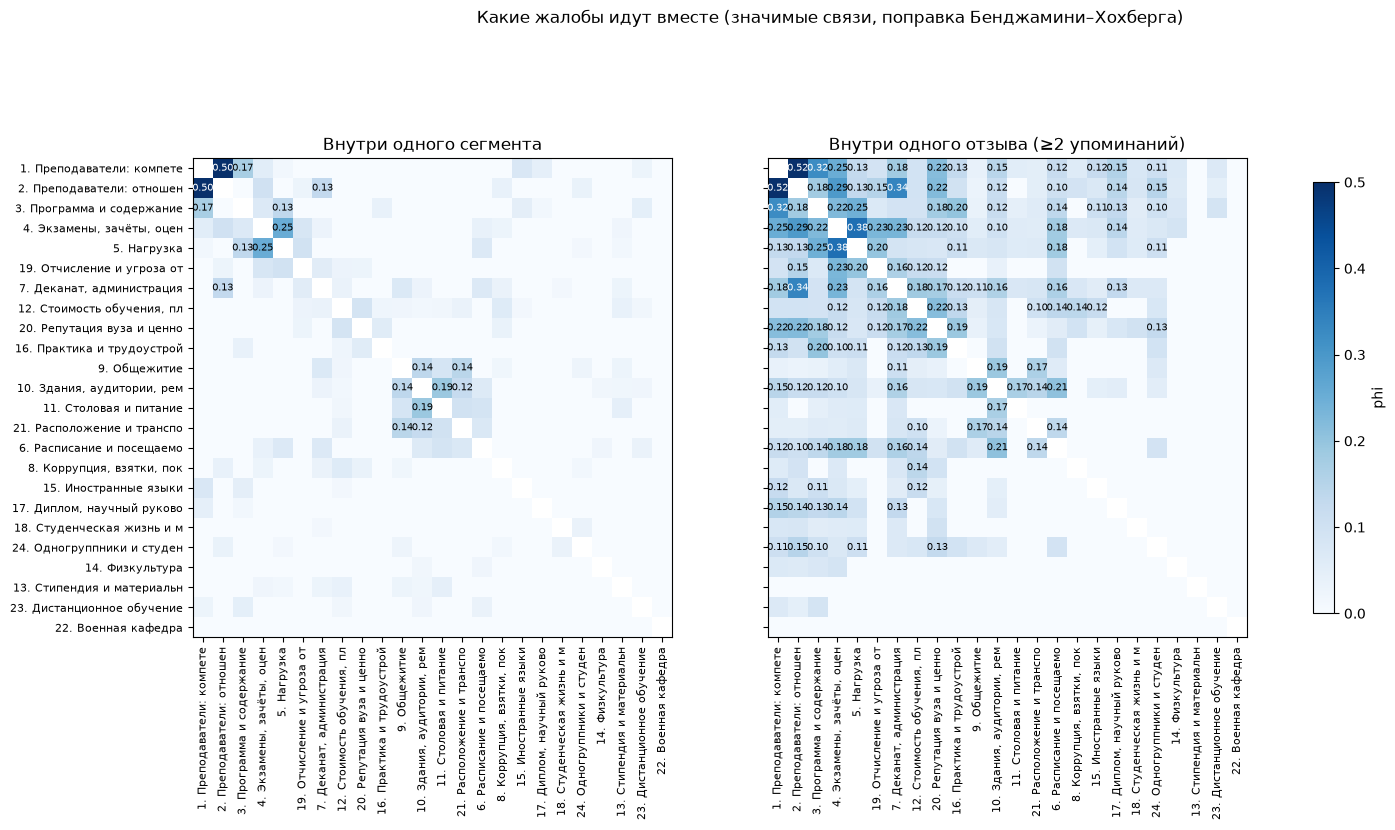

In [ ]:
import matplotlib.pyplot as plt

def phi_matrix(d):
    m = pd.DataFrame(0.0, index=names, columns=names)
    for _, r in d.iterrows():
        if r.p_adj < 0.05:
            m.loc[r.A, r.B] = m.loc[r.B, r.A] = r.phi
    return m

order = [1, 2, 3, 4, 5, 19, 7, 12, 20, 16, 9, 10, 11, 21, 6, 8, 15, 17, 18, 24, 14, 13, 23, 22]
ord_names = [short[c] for c in order]
fig, axes = plt.subplots(1, 2, figsize=(17, 8), sharey=True)
for ax, d, title in zip(axes, [seg_pairs, rev_pairs],
                        ["Внутри одного сегмента", "Внутри одного отзыва (≥2 упоминаний)"]):
    m = phi_matrix(d).loc[ord_names, ord_names]
    arr = m.to_numpy(copy=True)
    np.fill_diagonal(arr, np.nan)
    im = ax.imshow(arr, cmap="Blues", vmin=0, vmax=0.5)
    ax.set_xticks(range(len(m))); ax.set_xticklabels(m.columns, rotation=90, fontsize=8)
    ax.set_yticks(range(len(m))); ax.set_yticklabels(m.index, fontsize=8)
    ax.set_title(title)
    for i in range(len(m)):
        for j in range(len(m)):
            v = arr[i, j]
            if v == v and v >= 0.1:
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                        color="white" if v > 0.3 else "black")
fig.colorbar(im, ax=axes, shrink=0.7, label="phi")
fig.suptitle("Какие жалобы идут вместе (значимые связи, поправка Бенджамини–Хохберга)", y=0.98)
plt.savefig("complaints_cooccurrence.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
from scipy.stats import fisher_exact

asp_ids = [377, 451, 548, 569, 1076, 1158, 1648, 1944, 1959, 2490, 2518, 2856, 2866, 2874, 3233, 3493, 3617, 3728]
rev["asp"] = rev.index.isin(asp_ids)
print("аспирантских отзывов в разметке:", rev.asp.sum(), "| авторы:")
print(rev[rev.asp].author.value_counts().to_string())

A = (nseg >= 1)
rows = []
for c in CATS:
    a, b = A.loc[rev.asp, f"c{c}"], A.loc[~rev.asp, f"c{c}"]
    p = fisher_exact([[a.sum(), (~a).sum()], [b.sum(), (~b).sum()]])[1]
    rows.append((c, CB[c][:38], f"{a.sum()}/{len(a)}", round(a.mean(), 2), round(b.mean(), 2), round(a.mean() - b.mean(), 2), round(p, 3)))
tab = pd.DataFrame(rows, columns=["cat", "название", "аспиранты", "доля асп.", "доля остальных", "разница", "p (сырое)"])
print(tab.sort_values("доля асп.", ascending=False).to_string(index=False))

аспирантских отзывов в разметке: 18 | авторы:
author
Выпускник этого вуза    14
Студент этого вуза       3
Некто                    1
 cat                               название аспиранты  доля асп.  доля остальных  разница  p (сырое)
   2 Преподаватели: отношение к студентам (     11/18       0.61            0.68    -0.07      0.614
   1 Преподаватели: компетентность и качест     10/18       0.56            0.71    -0.15      0.192
   3 Программа и содержание курсов (устарел     10/18       0.56            0.64    -0.09      0.466
  20      Репутация вуза и ценность диплома     10/18       0.56            0.57    -0.01      1.000
   7 Деканат, администрация, бюрократия, оч      9/18       0.50            0.52    -0.02      1.000
  10 Здания, аудитории, ремонт, оборудовани      8/18       0.44            0.38     0.06      0.631
  12 Стоимость обучения, платное и бюджет,       8/18       0.44            0.32     0.13      0.309
   9                              Общежитие      7/18     

{'Студент': 2505, 'Выпускник': 913, 'Отчисленный': 121}
 cat                               название  Студент  Выпускник  Отчисленный  вып/студ  отч/студ        p_adj
  17    Диплом, научный руководитель, наука      1.1        4.5          1.0      4.13      0.87 7.944591e-58
  16             Практика и трудоустройство      3.2        7.0          3.5      2.20      1.10 1.219042e-32
  19         Отчисление и угроза отчисления      3.6        3.1         11.5      0.86      3.17 2.749168e-23
   2 Преподаватели: отношение к студентам (     18.9       21.7         27.7      1.15      1.47 3.559482e-10
  20      Репутация вуза и ценность диплома     14.0       16.0         18.9      1.14      1.35 1.141826e-08
   4 Экзамены, зачёты, оценивание, баллы, п     12.3       11.7         20.3      0.95      1.65 5.339045e-06
   7 Деканат, администрация, бюрократия, оч     13.3       14.2         16.8      1.07      1.27 1.868461e-04
   1 Преподаватели: компетентность и качест     18.7       20.8 

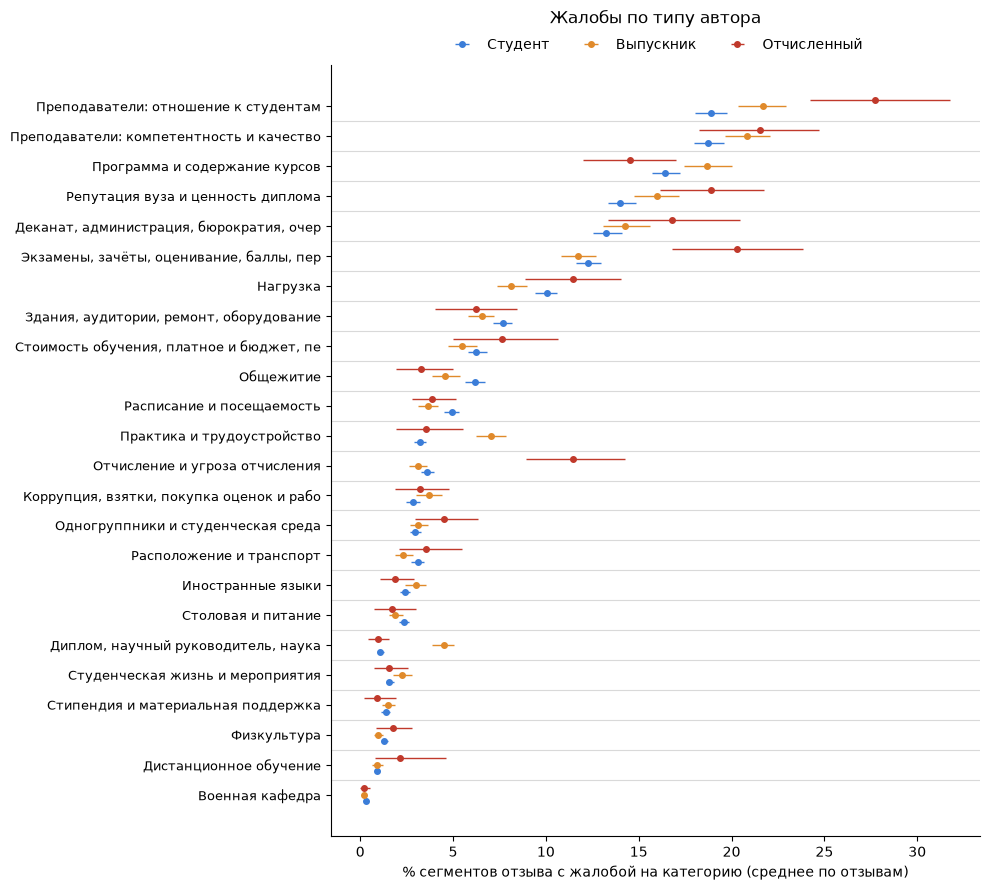

In [ ]:
from scipy.stats import kruskal, spearmanr
import matplotlib.pyplot as plt

def bh(p):
    p = np.asarray(p); o = np.argsort(p); m = len(p)
    adj = np.minimum.accumulate((p[o] * m / np.arange(1, m + 1))[::-1])[::-1]
    out = np.empty(m); out[o] = np.minimum(adj, 1); return out

n_seg = segs.groupby("id").size()
f = nseg.div(n_seg, axis=0)
assert (f.index == rev.index).all()

G = {"Студент": "Студент этого вуза", "Выпускник": "Выпускник этого вуза", "Отчисленный": "Отчисленный"}
idx = {k: rev.index[rev.author == v] for k, v in G.items()}
print({k: len(v) for k, v in idx.items()})

rng = np.random.default_rng(1)
rows, ci = [], {}
for c in CATS:
    col = f"c{c}"; x = {k: f.loc[i, col].to_numpy() for k, i in idx.items()}
    p = kruskal(*x.values())[1]
    row = {"cat": c, "название": CB[c][:38], **{k: v.mean() for k, v in x.items()}, "p": p}
    rows.append(row)
    for k, v in x.items():
        b = [v[rng.integers(0, len(v), len(v))].mean() for _ in range(500)]
        ci[(c, k)] = np.percentile(b, [2.5, 97.5])
tab = pd.DataFrame(rows); tab["p_adj"] = bh(tab.p)
tab["отч/студ"] = (tab["Отчисленный"] / tab["Студент"]).round(2)
tab["вып/студ"] = (tab["Выпускник"] / tab["Студент"]).round(2)
show = tab.copy()
for k in G: show[k] = (show[k] * 100).round(1)
print(show.sort_values("p_adj")[["cat", "название", *G, "вып/студ", "отч/студ", "p_adj"]].to_string(index=False))

t = tab.assign(tot=f[cols].mean().values).sort_values("tot")
fig, ax = plt.subplots(figsize=(10, 9)); y = np.arange(len(t))
for j, (k, colr) in enumerate(zip(G, ["#3b7dd8", "#e08a2b", "#c0392b"])):
    off = (j - 1) * 0.22
    ax.errorbar(t[k] * 100, y + off, xerr=[(t[k] - [ci[(c, k)][0] for c in t.cat]) * 100,
                                         ([ci[(c, k)][1] for c in t.cat] - t[k]) * 100],
                fmt="o", color=colr, ms=4, lw=1, label=k)
for yy in y[:-1] + 0.5:
    ax.axhline(yy, color="#d9d9d9", lw=0.8, zorder=0)
ax.set_yticks(y); ax.set_yticklabels([CB[c].split(" (")[0][:40]
                                      for c, p in zip(t.cat, t.p_adj)], fontsize=9)
ax.set_xlabel("% сегментов отзыва с жалобой на категорию (среднее по отзывам)")
ax.set_title("Жалобы по типу автора", pad=30)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=len(G), frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("by_author.png", dpi=150); plt.show()

 cat                               название    rho  p_adj
   4 Экзамены, зачёты, оценивание, баллы, п  0.142 0.0000
   3 Программа и содержание курсов (устарел  0.125 0.0000
  17    Диплом, научный руководитель, наука  0.124 0.0000
  16             Практика и трудоустройство  0.118 0.0000
   6 Расписание и посещаемость (окна, пары   0.101 0.0000
   2 Преподаватели: отношение к студентам (  0.102 0.0000
  23                 Дистанционное обучение  0.099 0.0000
  21               Расположение и транспорт  0.088 0.0000
  10 Здания, аудитории, ремонт, оборудовани  0.088 0.0000
  19         Отчисление и угроза отчисления  0.077 0.0000
  14                            Физкультура  0.075 0.0000
   5                               Нагрузка  0.074 0.0000
   1 Преподаватели: компетентность и качест  0.073 0.0000
   7 Деканат, администрация, бюрократия, оч  0.069 0.0000
   9                              Общежитие -0.065 0.0001
  18       Студенческая жизнь и мероприятия  0.060 0.0004
  12 Стоимость

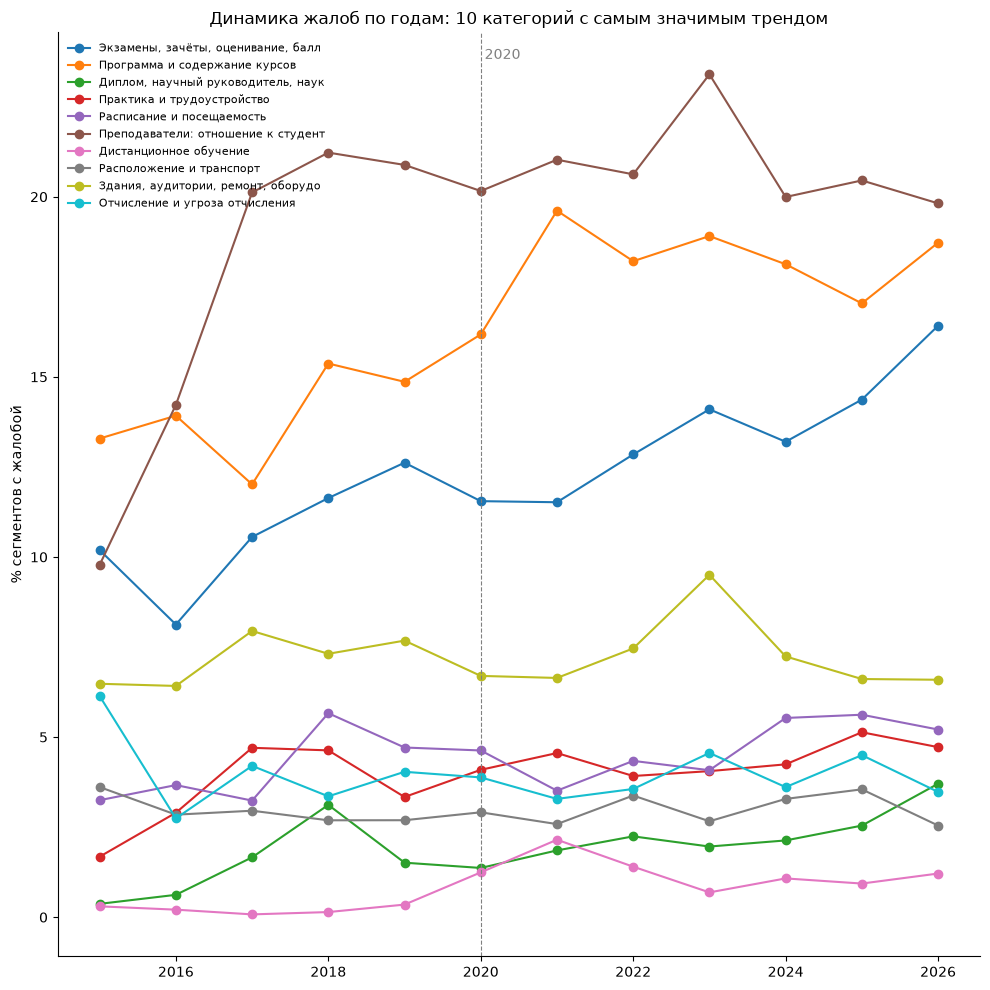

In [ ]:
yr = rev.year.astype(int)
ok = rev.index[(yr >= 2015) & (yr <= 2026)]
tr = []
for c in CATS:
    r_, p_ = spearmanr(yr.loc[ok], f.loc[ok, f"c{c}"])
    tr.append((c, CB[c][:38], round(r_, 3), p_))
tr = pd.DataFrame(tr, columns=["cat", "название", "rho", "p"]); tr["p_adj"] = bh(tr.p)
print(tr.sort_values("p_adj").assign(p_adj=lambda d: d.p_adj.round(4)).drop(columns="p").to_string(index=False))

top6 = list(tr.sort_values("p_adj").cat.head(10))
fig, ax = plt.subplots(figsize=(10, 10))
for c in top6:
    m = f[f"c{c}"].groupby(yr).mean() * 100
    se = f[f"c{c}"].groupby(yr).std() / np.sqrt(yr.value_counts().sort_index()) * 100
    ax.plot(m.index, m.values, marker="o", label=CB[c].split(" (")[0][:34])
ax.axvline(2020, color="gray", ls="--", lw=0.8); ax.text(2020.05, ax.get_ylim()[1] * 0.97, "2020", color="gray")
ax.set_ylabel("% сегментов с жалобой"); ax.set_title("Динамика жалоб по годам: 10 категорий с самым значимым трендом")
ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("by_year.png", dpi=150); plt.show()

вузов: 28, отзывов: 2218


C:\Users\qu\AppData\Local\Temp\ipykernel_35664\1481752537.py:17: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  row_order = ratio.mean(1).sort_values(ascending=False).index


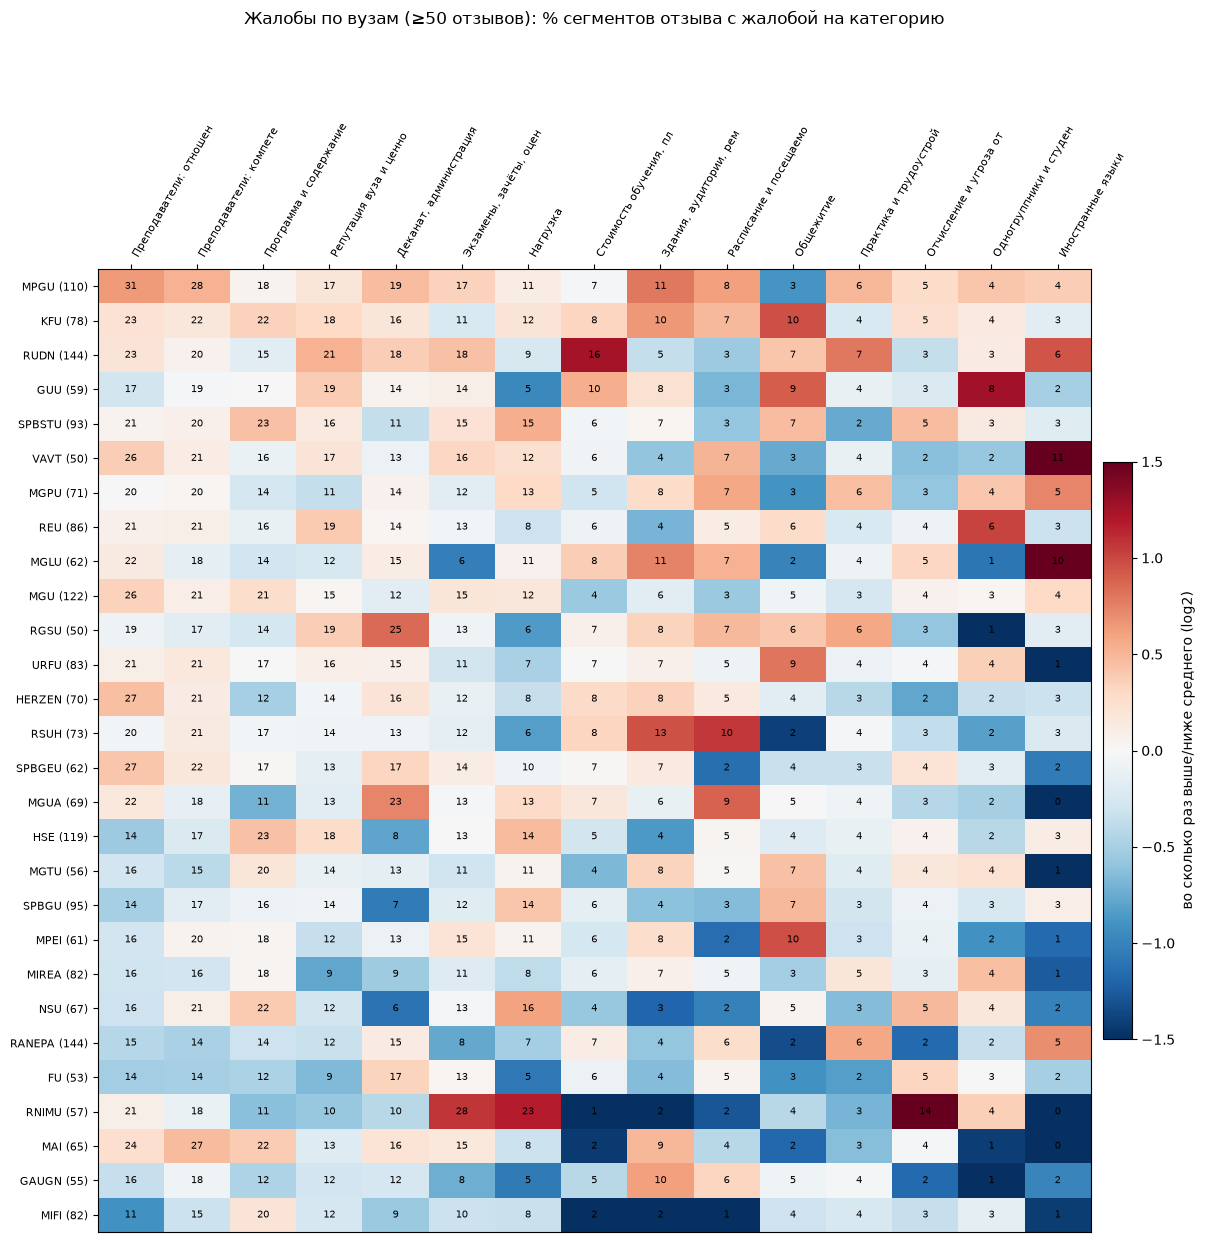


Общежитие | p_adj=1.26e-09 | в среднем 4.9%
  меньше всего: RSUH 1.9, RANEPA 2.0, MAI 2.2
  больше всего: KFU 9.6, MPEI 9.6, GUU 9.2

Здания, аудитории, ремонт, оборудование | p_adj=2.57e-16 | в среднем 6.4%
  меньше всего: RNIMU 1.6, MIFI 1.9, NSU 2.8
  больше всего: RSUH 12.5, MPGU 11.1, MGLU 10.8

Деканат, администрация, бюрократия, очер | p_adj=2.61e-11 | в среднем 13.8%
  меньше всего: NSU 6.4, SPBGU 6.7, HSE 8.0
  больше всего: RGSU 24.7, MGUA 22.8, MPGU 19.0

Программа и содержание курсов (устарело, | p_adj=3.46e-08 | в среднем 17.2%
  меньше всего: MGUA 10.5, RNIMU 11.1, HERZEN 12.1
  больше всего: SPBSTU 23.2, HSE 23.2, NSU 22.5

Экзамены, зачёты, оценивание, баллы, пер | p_adj=4.3e-08 | в среднем 13.1%
  меньше всего: MGLU 6.4, RANEPA 7.7, GAUGN 7.9
  больше всего: RNIMU 27.6, RUDN 17.8, MPGU 16.7

Преподаватели: компетентность и качество | p_adj=3.14e-05 | в среднем 19.3%
  меньше всего: FU 13.6, RANEPA 13.7, MGTU 14.6
  больше всего: MPGU 27.7, MAI 26.8, SPBGEU 21.6


In [ ]:
MIN = 50
vc = rev.univ.value_counts(); big = vc[vc >= MIN].index
sub = rev.index[rev.univ.isin(big)]
fu = f.loc[sub]; ug = rev.loc[sub, "univ"]
mean_u = fu.groupby(ug).mean()
overall = fu.mean()
print(f"вузов: {len(big)}, отзывов: {len(sub)}")

pk = pd.Series({c: kruskal(*[fu.loc[ug == u, f"c{c}"] for u in big])[1] for c in CATS})
padj = pd.Series(bh(pk.values), index=pk.index)

UNREL = {2, 5, 20, 21, 6, 12, 16}
sel = [c for c in sorted(CATS, key=lambda c: -overall[f"c{c}"]) if overall[f"c{c}"] >= 0.03]
M = mean_u[[f"c{c}" for c in sel]]
ratio = np.log2((M / overall[M.columns]).clip(lower=0.25))
row_order = ratio.mean(1).sort_values(ascending=False).index
M, ratio = M.loc[row_order], ratio.loc[row_order]

fig, ax = plt.subplots(figsize=(13, 0.34 * len(M) + 3))
im = ax.imshow(ratio.values, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
for i in range(len(M)):
    for j in range(len(sel)):
        ax.text(j, i, f"{M.values[i, j] * 100:.0f}", ha="center", va="center", fontsize=7.5)
labels = [CB[c].split(" (")[0][:22] for c in sel]
ax.set_xticks(range(len(sel))); ax.set_xticklabels(labels, rotation=60, ha="left", fontsize=8)
ax.xaxis.tick_top()
ax.set_yticks(range(len(M))); ax.set_yticklabels([f"{u} ({vc[u]})" for u in M.index], fontsize=8)
cb = fig.colorbar(im, shrink=0.6, pad=0.01); cb.set_label("во сколько раз выше/ниже среднего (log2)")
ax.set_title(f"Жалобы по вузам (≥{MIN} отзывов): % сегментов отзыва с жалобой на категорию", pad=70)
plt.tight_layout(); plt.savefig("by_univ.png", dpi=150, bbox_inches="tight"); plt.show()

for c in [9, 10, 7, 3, 4, 1]:
    s = (mean_u[f"c{c}"] * 100).round(1).sort_values()
    print(f"\n{CB[c][:40]} | p_adj={padj[c]:.3g} | в среднем {overall[f'c{c}']*100:.1f}%")
    print("  меньше всего:", ", ".join(f"{u} {v}" for u, v in s.head(3).items()))
    print("  больше всего:", ", ".join(f"{u} {v}" for u, v in s.tail(3)[::-1].items()))

In [ ]:
import pandas as pd

u = pd.read_csv("unis.csv", encoding="utf-8")
text = u["Feedback"].astype(str)
words = text.str.split().str.len()
year = u["Date"].str.split().str[-1].astype(int)
views = pd.to_numeric(u["Views"], errors="coerce")
useful = pd.to_numeric(u["Usefulness"], errors="coerce")
vuz = u["University"].value_counts()

def counts(s):
    return " | ".join(f"{k} {v:,}".replace(",", " ") for k, v in s.value_counts().items())

rows = [
    ("Отзывов", f"{len(u):,}".replace(",", " ")),
    ("Вузов", f"{vuz.size} (медиана {vuz.median():.0f} отзыва на вуз, максимум {vuz.max()}: {vuz.idxmax()})"),
    ("Факультетов / подразделений", u["Department"].nunique()),
    ("Период", f"{year.min()}–{year.max()}"),
    ("Слов всего", f"{words.sum():,}".replace(",", " ")),
    ("Символов всего", f"{text.str.len().sum():,}".replace(",", " ")),
    ("Слов в отзыве", f"среднее {words.mean():.0f}, медиана {words.median():.0f}, от {words.min()} до {words.max()}"),
    ("Авторы", counts(u["Position"])),
    ("Оценка отзыва (тон)", counts(u["Tone"])),
    ("Отзывов по годам", " | ".join(f"{y}: {n}" for y, n in year.value_counts().sort_index().items())),
    ("Просмотров", ", ".join(f"{name} {f'{val:,.0f}'.replace(',', ' ')}" for name, val in
                         [("среднее", views.mean()), ("медиана", views.median()), ("максимум", views.max())])),
    ("«Полезно»", f"среднее {useful.mean():.1f}, медиана {useful.median():.0f}, максимум {useful.max():.0f}"),
]
summary = pd.DataFrame(rows, columns=["Показатель", "Значение"])

display(summary.style.hide(axis="index")
        .set_properties(subset=["Значение"], **{"text-align": "left", "white-space": "normal"})
        .set_properties(subset=["Показатель"], **{"font-weight": "bold", "text-align": "left"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}]))

summary.to_csv("dataset_summary.csv", index=False, sep=";", encoding="utf-8-sig")   # открывается в Excel

Показатель,Значение
Отзывов,3 818
Вузов,"241 (медиана 3 отзыва на вуз, максимум 147: RANEPA)"
Факультетов / подразделений,722
Период,2015–2026
Слов всего,2 144 083
Символов всего,14 393 623
Слов в отзыве,"среднее 562, медиана 431, от 61 до 5753"
Авторы,Студент этого вуза 2 515 | Выпускник этого вуза 921 | Некто 188 | Отчисленный 123 | Абитуриент этого вуза 28 | Просто человек 26 | Преподаватель/администрация вуза 17
Оценка отзыва (тон),negative 1 935 | positive 1 074 | neutral 809
Отзывов по годам,2015: 109 | 2016: 136 | 2017: 136 | 2018: 340 | 2019: 410 | 2020: 459 | 2021: 483 | 2022: 487 | 2023: 471 | 2024: 335 | 2025: 272 | 2026: 180


C:\Users\qu\AppData\Local\Temp\ipykernel_35664\4124977175.py:5: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct["total"] = ct.sum(1)


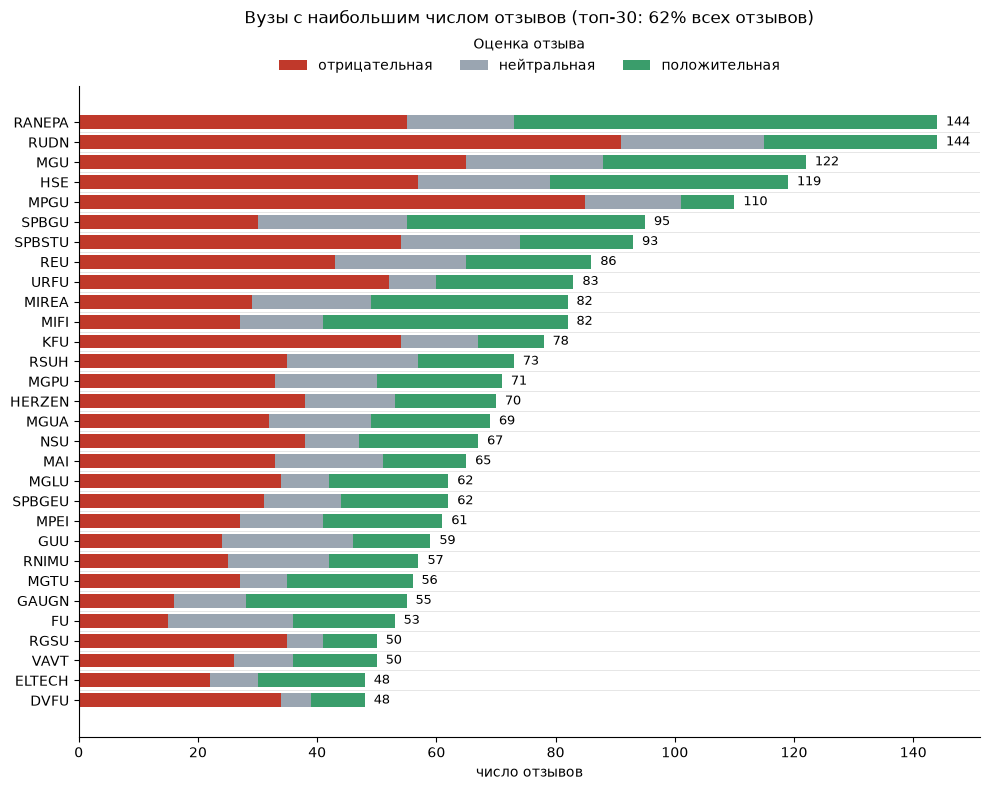

In [ ]:
import matplotlib.pyplot as plt

TOP = 30
ct = pd.crosstab(rev.univ, rev.tone).reindex(columns=["negative", "neutral", "positive"], fill_value=0)
ct["total"] = ct.sum(1)
ct = ct.sort_values("total", ascending=False).head(TOP).iloc[::-1]

colors = {"negative": "#c0392b", "neutral": "#9aa5b1", "positive": "#3a9d6b"}
names = {"negative": "отрицательная", "neutral": "нейтральная", "positive": "положительная"}

fig, ax = plt.subplots(figsize=(10, 8))
left = np.zeros(len(ct))
for t in ["negative", "neutral", "positive"]:
    ax.barh(ct.index, ct[t], left=left, color=colors[t], label=names[t], height=0.7)
    left += ct[t].to_numpy()
for y, v in enumerate(ct.total):
    ax.text(v + 1.5, y, str(v), va="center", fontsize=9)
for yy in np.arange(len(ct) - 1) + 0.5:
    ax.axhline(yy, color="#e6e6e6", lw=0.7, zorder=0)
share = ct.total.sum() / len(rev)
ax.set_xlabel("число отзывов")
ax.set_title(f"Вузы с наибольшим числом отзывов (топ-{TOP}: {share:.0%} всех отзывов)", pad=45)
ax.legend(title="Оценка отзыва", loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("top_univ_reviews.png", dpi=150); plt.show()

In [ ]:
u = pd.read_csv("unis.csv", encoding="utf-8")

kept = pd.read_pickle("reviews_clean.pkl")
removed = pd.read_pickle("reviews_removed_dups.pkl")
clean = pd.concat([kept[["id", "text_clean"]], removed[["id", "text_clean"]]]).set_index("id")["text_clean"]
assert len(clean) == len(u) and set(clean.index) == set(range(len(u)))

out = u.copy()
out["Feedback"] = out.index.map(clean)

MONTHS = {"января": 1, "февраля": 2, "марта": 3, "апреля": 4, "мая": 5, "июня": 6,
          "июля": 7, "августа": 8, "сентября": 9, "октября": 10, "ноября": 11, "декабря": 12}

def parse_date(s):
    d, m, y = str(s).split()
    return pd.Timestamp(int(y), MONTHS[m.lower()], int(d))

out["Date"] = out["Date"].map(parse_date).dt.strftime("%Y-%m-%d")

out.to_csv("unis_clean.csv", index=False, encoding="utf-8")
print(out.shape, out["Feedback"].isna().sum(), out["Date"].min(), out["Date"].max())

(3818, 8) 0 2015-10-30 2026-10-06


In [ ]:
all_years = sorted(df['Date'].str.split().str[-1].unique().astype(int))
print(all_years)

[np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]


In [ ]:
aspirants = []

for index, row in df.iterrows():
    if 'аспирант' in row['Feedback']:
        aspirants.append(row['Feedback'])

for index, a in enumerate(aspirants):
    print(index, a, '\n\n')

0 Здравствуйте! Меня зовут Александр. Я живу в городе Барнауле. В 2016 году я закончил с отличием бакалавриат Алтайского государственного университета, факультет массовых коммуникаций, филологии и политологии по направлению "Философия" и поступил в магистратуру по этому же направлению, где сейчас и обучаюсь.В Алтайский государственный университет я поступил в 2012 году, на философию поступил можно сказать почти случайно-не хватило баллов на первые приоритеты (историю и политологию). Проходил по баллам на историю в педуниверситете (тогда он ещё был педакадемией), но в итоге остановил свой выбор на АлтГУ и философии, о чём в дальнейшем ни разу не пожалел! Университет мне сразу понравился, большие корпуса, квалифицированные и компетентные преподаватели, имеющие в своём большинстве учёную степень и учёное звание, готовые ответить на любой вопрос, так или иначе касающийся преподаваемых предметов, приятный студенческий контингент. В университет поступают целеустремлённые, умные люди, с котор

In [ ]:
with open('asps.txt', 'w', encoding='utf-8') as f:
    for index, i in enumerate(aspirants):
        s = str(index) + ' ' + i + '\n' + '\n'
        f.write(s)

In [ ]:
df = pd.read_csv("unis_clean.csv")
df.head(5)

,University,Position,Department,Feedback,Date,Tone,Views,Usefulness
0,ALTGAKI,Студент этого вуза,Факультет художественного творчества,"Итак, для тех кто необдуманно хочет поступать ...",2024-07-02,negative,12058,15
1,AGPU,Выпускник этого вуза,Психолого-педагогический факультет,"Если вы собрались выучиться на психолога, то д...",2023-08-14,negative,5380,15
2,AGNIRT,Студент этого вуза,Факультет экономических и гуманитарных дисциплин,Я поступила в ВШН в 2023 году на 1 курс менедж...,2024-03-07,positive,22130,39
3,ADYGNET,Просто человек,Факультет математики и компьютерных наук,Информации о этом ВУЗе в интернете нет (помимо...,2021-08-21,neutral,13881,30
4,ASU,Отчисленный,Факультет иностранных языков,"Вышло так, что в 2018 выкатили сложный профиль...",2021-01-09,neutral,15164,35
